# Digital Twin Blé — v6 SimPy Engine + Normes (corrigé)

6 SimPy Engine + Normes (corrigé)

**Nouvelle architecture v5 :**
```
┌─────────────────────────────────────────────────────┐
│              PHASE 1 — NORMES (au démarrage)        │
│  Calcul des normes de référence depuis les données  │
│  (baseline génomique + paramètres WOFOST normaux)   │
└────────────────────┬────────────────────────────────┘
                     ▼
┌─────────────────────────────────────────────────────┐
│         PHASE 2 — SIMPY DATA ENGINE                 │
│  Simulation continue du temps (jour par jour)       │
│  Génération météo synthétique Tunisie               │
│  Événements : stress hydrique, maladie, récolte     │
└────────────────────┬────────────────────────────────┘
                     ▼
┌─────────────────────────────────────────────────────┐
│         PHASE 3 — DIGITAL TWIN WOFOST               │
│  Simulation WOFOST avec paramètres SNP              │
│  Comparaison vs normes → alertes                    │
│  Dashboard temps réel                               │
└─────────────────────────────────────────────────────┘
```

**Références :**
- IAAA-Lab (2024). AgriculturalDigitalTwinPlatform. DOI: 10.5281/zenodo.15697049
- Lutz et al. (2019). SimPy: Discrete-event simulation. https://simpy.readthedocs.io
- Van Diepen et al. (1989). WOFOST. Agricultural Systems, 29(1), 1–24.

## 0. Installation

In [ ]:
!pip install -q simpy biopython pcse pandas numpy matplotlib seaborn \
    scikit-learn openpyxl joblib


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 103.7/103.7 kB 3.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 52.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 880.3/880.3 kB 47.0 MB/s eta 0:00:00


## 1. Imports & Configuration

In [ ]:
import os, sqlite3, datetime, math, re, time, json, warnings, random
from collections import namedtuple, Counter
from dataclasses import dataclass, field
from typing import Dict, List, Optional, Tuple, Any

import simpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display, HTML

import pcse
import pcse.settings as settings
from pcse.tests.db_input import (
    GridWeatherDataProvider, fetch_soildata, fetch_sitedata,
    fetch_cropdata, AgroManagementDataProvider
)
from pcse.base import ParameterProvider, WeatherDataProvider, WeatherDataContainer
from pcse.models import Wofost72_WLP_CWB
from pcse.util import reference_ET
from pcse.exceptions import PCSEError

warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
np.random.seed(42)

EXCEL_PATH  = 'predictions_croisements (4) (1).xlsx'
DB_LOCATION = os.path.join(settings.PCSE_USER_HOME, 'pcse.db')

def namedtuple_factory(cursor, row):
    fields = [col[0] for col in cursor.description]
    return namedtuple('Row', fields)(*row)

def open_db():
    conn = sqlite3.connect(DB_LOCATION)
    conn.row_factory = namedtuple_factory
    return conn

print(f'pcse {pcse.__version__} | simpy {simpy.__version__} | DB: {DB_LOCATION}')


Building PCSE demo database at: /tmp/.pcse/pcse.db ... OK
pcse 6.0.12 | simpy 4.1.1 | DB: /tmp/.pcse/pcse.db


## 2. Chargement des données Excel

In [ ]:
# Chargement robuste avec imputation des valeurs manquantes
df = pd.read_excel(EXCEL_PATH)
pred_cols = ['pred_drought', 'pred_salt', 'pred_yield', 'pred_disease']
snp_cols  = [c for c in df.columns if 'SNP' in c]

# Imputation médiane si NaN
for col in pred_cols:
    n_miss = df[col].isna().sum()
    if n_miss > 0:
        df[col].fillna(df[col].median(), inplace=True)
        print(f'[WARN] {col}: {n_miss} NaN imputées par médiane')

print(f'Croisements : {len(df)} | SNP : {len(snp_cols)} | NaN restants : {df[pred_cols].isna().sum().sum()}')
df[pred_cols].describe().round(3)


Croisements : 720 | SNP : 159 | NaN restants : 0


,pred_drought,pred_salt,pred_yield,pred_disease
count,720.000,720.000,720.000,720.000
mean,0.431,0.538,0.377,0.516
std,0.032,0.038,0.010,0.033
min,0.330,0.443,0.332,0.402
25%,0.406,0.508,0.370,0.493
50%,0.434,0.535,0.377,0.517
75%,0.454,0.567,0.384,0.542
max,0.541,0.667,0.409,0.624


## 3. PHASE 1 — CALCUL DES NORMES DE RÉFÉRENCE

**Concept :** Au démarrage du digital twin, on établit des **normes** (baseline) :
- Normes génomiques (scores SNP moyens, percentiles P10/P50/P90)
- Normes WOFOST (paramètres de référence pour un croisement moyen)
- Normes météo Tunisie (température, pluie, rayonnement saisonniers)
- Seuils d'alerte pour détecter les déviations

In [ ]:
# ─── Normalisation des scores SNP ───────────────────────────────────────────
RANGES = {
    'pred_drought': (df['pred_drought'].min(), df['pred_drought'].max()),
    'pred_yield':   (df['pred_yield'].min(),   df['pred_yield'].max()),
    'pred_disease': (df['pred_disease'].min(), df['pred_disease'].max()),
    'pred_salt':    (df['pred_salt'].min(),     df['pred_salt'].max()),
}

def normalize(val, col):
    lo, hi = RANGES[col]
    return max(0.0, min(1.0, (val - lo) / (hi - lo + 1e-9)))

def snp_to_wofost(row):
    pd_n  = normalize(row['pred_drought'], 'pred_drought')
    py_n  = normalize(row['pred_yield'],   'pred_yield')
    pdi_n = normalize(row['pred_disease'], 'pred_disease')
    ps_n  = normalize(row['pred_salt'],    'pred_salt')
    return {
        'CFET':  round(0.50 + pd_n * 0.50, 3),
        'DEPNR': round(5.00 - pd_n * 3.50, 2),
        'TDWI':  round(50.0 + py_n * 160., 1),
        'SPAN':  round(25.0 + py_n * 13.,  1),
        'PERDL': round(0.030 - pdi_n*0.020, 4),
        'SMFCF': round(0.200 + ps_n  * 0.200, 3)
    }

# ─── Calcul des normes ──────────────────────────────────────────────────────
@dataclass
class NormesReference:
    """Normes de référence établies au démarrage du Digital Twin."""

    # Normes génomiques
    genomique: Dict = field(default_factory=dict)

    # Normes WOFOST (paramètres de référence)
    wofost_baseline: Dict = field(default_factory=dict)
    wofost_p10: Dict      = field(default_factory=dict)
    wofost_p90: Dict      = field(default_factory=dict)

    # Normes météo Tunisie (par mois)
    meteo_baseline: Dict  = field(default_factory=dict)

    # Seuils d'alerte
    seuils_alerte: Dict   = field(default_factory=dict)

    # Résultats WOFOST de référence
    twso_baseline: float  = 0.0
    twso_p10: float       = 0.0
    twso_p90: float       = 0.0
    lai_max_baseline: float = 0.0


def run_wofost_base(row):
    """Simulation WOFOST de base (réutilisée dans les phases suivantes)."""
    DBconn = open_db()
    cropd = fetch_cropdata(DBconn, 31031, 2000, 1)
    soild = fetch_soildata(DBconn, 31031)
    sited = fetch_sitedata(DBconn, 31031, 2000)
    agro  = AgroManagementDataProvider(DBconn, 31031, 1, 2000)
    wdp   = GridWeatherDataProvider(DBconn, grid_no=31031)
    DBconn.close()
    params = ParameterProvider(cropdata=cropd, soildata=soild, sitedata=sited)
    wofost_p = snp_to_wofost(row)
    for key, val in wofost_p.items():
        if key == 'SMFCF':
            params._soildata['SMFCF'] = val
        else:
            params._cropdata[key] = val
    model = Wofost72_WLP_CWB(params, wdp, agro)
    model.run_till_terminate()
    return pd.DataFrame(model.get_output())

def etablir_normes(df_crossings):
    """
    PHASE 1 — Établit toutes les normes de référence au démarrage.
    Ref : Hazel (1943), Van Diepen et al. (1989)
    """
    print('═'*55)
    print('PHASE 1 — CALCUL DES NORMES DE RÉFÉRENCE')
    print('═'*55)

    normes = NormesReference()

    # ── 1. Normes génomiques ─────────────────────────────────────────────
    normes.genomique = {}
    for col in pred_cols:
        normes.genomique[col] = {
            'mean':  round(df_crossings[col].mean(), 4),
            'std':   round(df_crossings[col].std(),  4),
            'p10':   round(df_crossings[col].quantile(0.10), 4),
            'p50':   round(df_crossings[col].quantile(0.50), 4),
            'p90':   round(df_crossings[col].quantile(0.90), 4),
            'min':   round(df_crossings[col].min(), 4),
            'max':   round(df_crossings[col].max(), 4),
        }

    print(f'\n[NORME 1] Normes génomiques ({len(df_crossings)} croisements)')
    for col, stats in normes.genomique.items():
        print(f'  {col:<20} μ={stats["mean"]:.4f} | P10={stats["p10"]:.4f} | P90={stats["p90"]:.4f}')

    # ── 2. Normes WOFOST (paramètres) ────────────────────────────────────
    wofost_all = df_crossings.apply(snp_to_wofost, axis=1, result_type='expand')
    wofost_params = ['CFET', 'DEPNR', 'TDWI', 'SPAN', 'PERDL', 'SMFCF']

    for p in wofost_params:
        normes.wofost_baseline[p] = round(wofost_all[p].mean(), 4)
        normes.wofost_p10[p]      = round(wofost_all[p].quantile(0.10), 4)
        normes.wofost_p90[p]      = round(wofost_all[p].quantile(0.90), 4)

    print(f'\n[NORME 2] Paramètres WOFOST de référence')
    for p in wofost_params:
        print(f'  {p:<8} baseline={normes.wofost_baseline[p]:.4f} | P10={normes.wofost_p10[p]:.4f} | P90={normes.wofost_p90[p]:.4f}')

    # ── 3. Normes météo Tunisie (climatologie mensuelle) ──────────────────
    # Source : données climatologiques Tunisie centrale (Maktar ~600m)
    normes.meteo_baseline = {
        'tmin_mensuel': [3.5, 4.0, 6.5, 9.5, 13.5, 18.0, 21.0, 21.5, 18.0, 14.0, 8.5, 4.5],  # Jan–Déc
        'tmax_mensuel': [13.0, 14.5, 17.5, 21.0, 26.5, 32.0, 36.0, 36.5, 31.0, 25.5, 18.5, 14.0],
        'pluie_mensuel': [28, 22, 25, 20, 15, 8, 3, 5, 18, 28, 30, 32],  # mm/mois
        'irrad_mensuel': [9.5, 11.5, 14.0, 17.0, 20.5, 23.5, 24.0, 22.5, 18.5, 14.0, 10.0, 8.5],  # MJ/m²/j
        'lat': 35.81, 'lon': 8.58, 'elev': 624.0
    }

    print(f'\n[NORME 3] Climatologie mensuelle Tunisie (Maktar)')
    mois = ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc']
    for i, m in enumerate(mois):
        print(f'  {m}: Tmin={normes.meteo_baseline["tmin_mensuel"][i]}°C '
              f'Tmax={normes.meteo_baseline["tmax_mensuel"][i]}°C '
              f'Pluie={normes.meteo_baseline["pluie_mensuel"][i]}mm '
              f'Irrad={normes.meteo_baseline["irrad_mensuel"][i]}MJ/m²')

    # ── 4. Seuils d'alerte ───────────────────────────────────────────────
    normes.seuils_alerte = {
        # Alerte si écart > N fois l'écart-type
        'genomique_zscore': 2.0,
        # Alerte si TWSO < X% de la norme
        'twso_critique_pct': 0.70,   # < 70% de la norme → alerte critique
        'twso_warning_pct':  0.85,   # < 85% de la norme → avertissement
        # Alerte météo
        'tmax_canicule': 38.0,        # °C — stress thermique
        'pluie_stress':  2.0,         # mm/j — stress hydrique si sous ce seuil
        'vent_alerte':   10.0,         # m/s
        # Alertes agronomiques
        'dvs_retard_semis': 15,        # jours de retard phénologique max
        'lai_insuffisant': 1.5,        # LAI trop faible → problème
    }

    print(f'\n[NORME 4] Seuils d\'alerte définis')
    for seuil, val in normes.seuils_alerte.items():
        print(f'  {seuil:<28}: {val}')

    # ── 5. Simulation WOFOST de référence (croisement moyen) ──────────────
    print(f'\n[NORME 5] Simulation WOFOST de référence...')
    row_median = df_crossings.loc[df_crossings['pred_yield'].sub(
        df_crossings['pred_yield'].median()).abs().idxmin()]

    try:
        out_ref = run_wofost_base(row_median)
        if not out_ref.empty and 'TWSO' in out_ref.columns:
            normes.twso_baseline  = round(out_ref['TWSO'].iloc[-1], 1)
            normes.lai_max_baseline = round(out_ref['LAI'].max(), 3)
            print(f'  TWSO baseline  = {normes.twso_baseline:.1f} kg/ha')
            print(f'  LAI max baseline = {normes.lai_max_baseline:.3f} m²/m²')
    except Exception as e:
        print(f'  [!] Simulation référence impossible : {e}')
        normes.twso_baseline    = 4500.0  # valeur par défaut littérature
        normes.twso_p10         = 3200.0
        normes.twso_p90         = 5800.0
        normes.lai_max_baseline = 3.5

    print('\n✅ Normes établies avec succès.')
    print('═'*55)
    return normes


print('Fonctions de normes définies. Lancement...')

Fonctions de normes définies. Lancement...


In [ ]:
# ── Lancement de la Phase 1 ──────────────────────────────────────────────────
NORMES = etablir_normes(df)

═══════════════════════════════════════════════════════
PHASE 1 — CALCUL DES NORMES DE RÉFÉRENCE
═══════════════════════════════════════════════════════

[NORME 1] Normes génomiques (720 croisements)
  pred_drought         μ=0.4311 | P10=0.3883 | P90=0.4699
  pred_salt            μ=0.5376 | P10=0.4909 | P90=0.5887
  pred_yield           μ=0.3767 | P10=0.3650 | P90=0.3894
  pred_disease         μ=0.5163 | P10=0.4731 | P90=0.5587

[NORME 2] Paramètres WOFOST de référence
  CFET     baseline=0.7402 | P10=0.6390 | P90=0.8320
  DEPNR    baseline=3.3187 | P10=2.6700 | P90=4.0300
  TDWI     baseline=142.9082 | P10=118.8900 | P90=169.0400
  SPAN     baseline=32.5483 | P10=30.6000 | P90=34.7000
  PERDL    baseline=0.0197 | P10=0.0159 | P90=0.0236
  SMFCF    baseline=0.2842 | P10=0.2420 | P90=0.3300

[NORME 3] Climatologie mensuelle Tunisie (Maktar)
  Jan: Tmin=3.5°C Tmax=13.0°C Pluie=28mm Irrad=9.5MJ/m²
  Fév: Tmin=4.0°C Tmax=14.5°C Pluie=22mm Irrad=11.5MJ/m²
  Mar: Tmin=6.5°C Tmax=17.5°C Pluie

## 4. Visualisation des normes établies

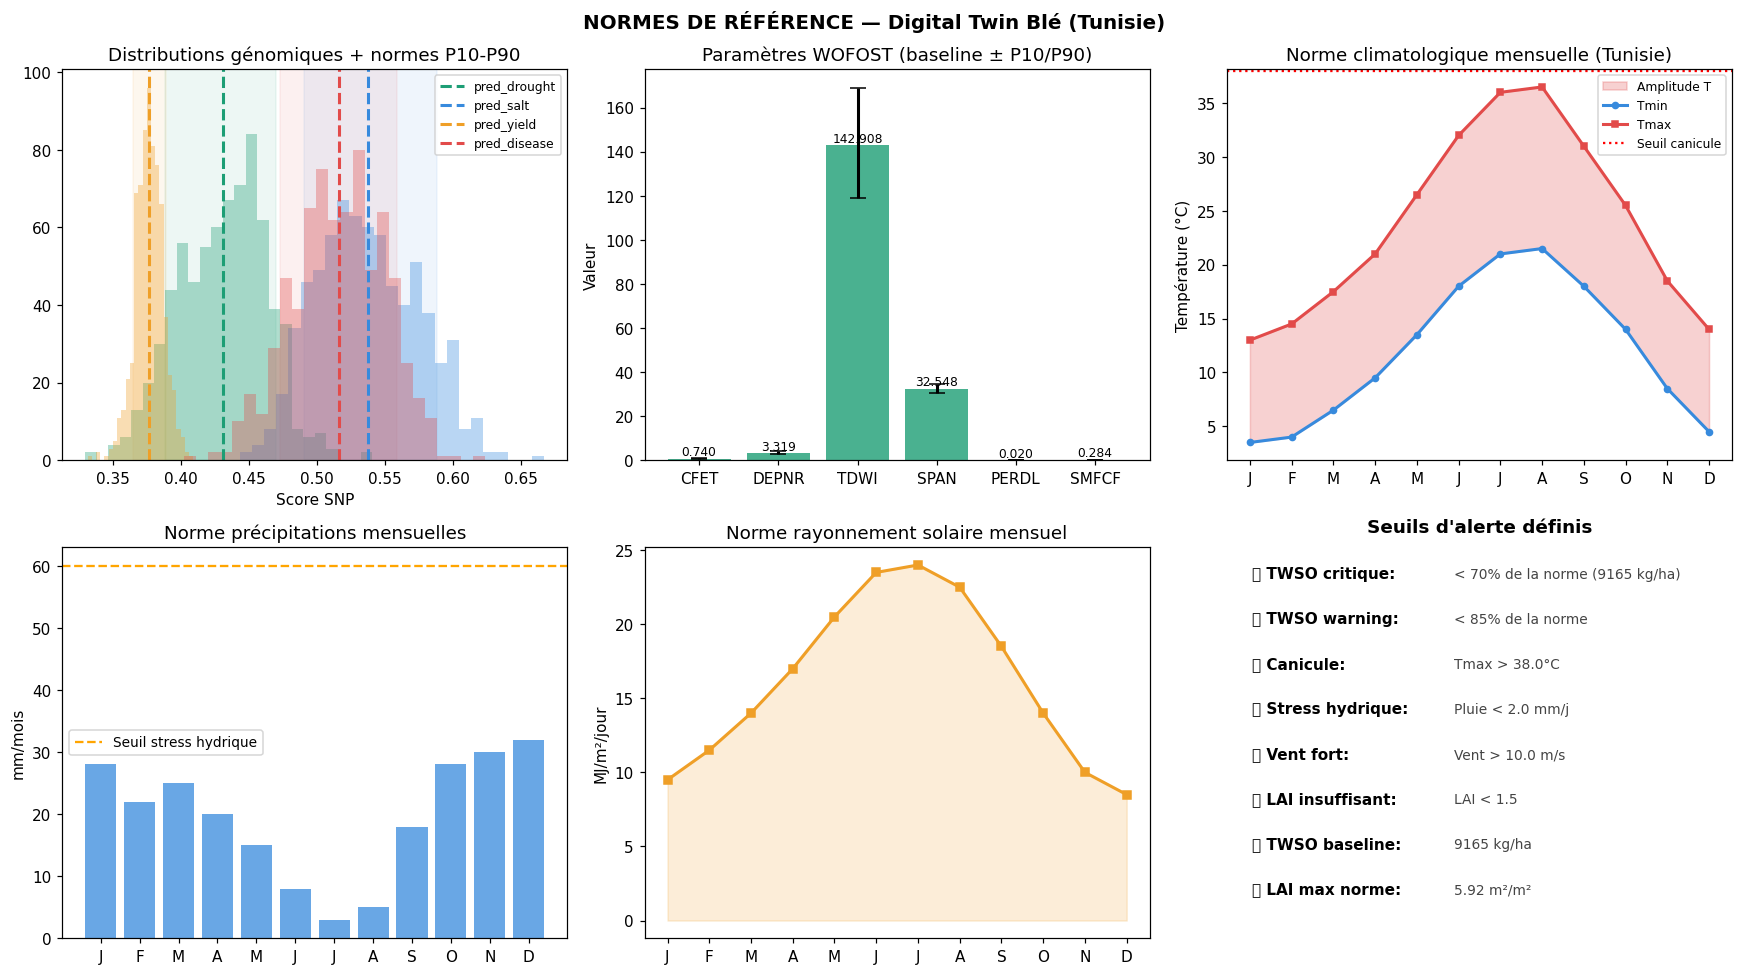

✅ Graphique normes sauvegardé.


In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle('NORMES DE RÉFÉRENCE — Digital Twin Blé (Tunisie)', fontsize=13, fontweight='bold')

colors = ['#1D9E75','#378ADD','#EF9F27','#E24B4A']

# Subplot 1 : Distribution des scores génomiques
ax = axes[0,0]
for i, col in enumerate(pred_cols):
    ax.axvline(NORMES.genomique[col]['mean'], color=colors[i], lw=2, label=col, ls='--')
    ax.axvspan(NORMES.genomique[col]['p10'], NORMES.genomique[col]['p90'],
               alpha=0.08, color=colors[i])
for i, col in enumerate(pred_cols):
    ax.hist(df[col], bins=25, alpha=0.35, color=colors[i])
ax.set_title('Distributions génomiques + normes P10-P90')
ax.legend(fontsize=8)
ax.set_xlabel('Score SNP')

# Subplot 2 : Paramètres WOFOST baseline
ax = axes[0,1]
params_wofost = list(NORMES.wofost_baseline.keys())
vals = [NORMES.wofost_baseline[p] for p in params_wofost]
errs_lo = [NORMES.wofost_baseline[p] - NORMES.wofost_p10[p] for p in params_wofost]
errs_hi = [NORMES.wofost_p90[p] - NORMES.wofost_baseline[p] for p in params_wofost]
bars = ax.bar(params_wofost, vals, color='#1D9E75', alpha=0.8, edgecolor='none')
ax.errorbar(params_wofost, vals, yerr=[errs_lo, errs_hi], fmt='none', color='black', capsize=5, lw=2)
ax.set_title('Paramètres WOFOST (baseline ± P10/P90)')
ax.set_ylabel('Valeur')
for bar, val in zip(bars, vals):
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.01, f'{val:.3f}',
            ha='center', va='bottom', fontsize=8)

# Subplot 3 : Climatologie mensuelle (Tmin/Tmax)
ax = axes[0,2]
mois = range(1,13)
tmin = NORMES.meteo_baseline['tmin_mensuel']
tmax = NORMES.meteo_baseline['tmax_mensuel']
ax.fill_between(mois, tmin, tmax, alpha=0.25, color='#E24B4A', label='Amplitude T')
ax.plot(mois, tmin, 'o-', color='#378ADD', lw=2, ms=4, label='Tmin')
ax.plot(mois, tmax, 's-', color='#E24B4A', lw=2, ms=4, label='Tmax')
ax.axhline(NORMES.seuils_alerte['tmax_canicule'], color='red', ls=':', lw=1.5, label='Seuil canicule')
ax.set_xticks(mois)
ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_title('Norme climatologique mensuelle (Tunisie)')
ax.set_ylabel('Température (°C)')
ax.legend(fontsize=8)

# Subplot 4 : Précipitations mensuelles
ax = axes[1,0]
pluie = NORMES.meteo_baseline['pluie_mensuel']
bars = ax.bar(mois, pluie, color='#378ADD', alpha=0.75, edgecolor='none')
ax.axhline(NORMES.seuils_alerte['pluie_stress']*30, color='orange', ls='--', lw=1.5, label='Seuil stress hydrique')
ax.set_xticks(mois)
ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_title('Norme précipitations mensuelles')
ax.set_ylabel('mm/mois')
ax.legend(fontsize=9)

# Subplot 5 : Rayonnement mensuel
ax = axes[1,1]
irrad = NORMES.meteo_baseline['irrad_mensuel']
ax.plot(mois, irrad, 's-', color='#EF9F27', lw=2, ms=5)
ax.fill_between(mois, 0, irrad, alpha=0.18, color='#EF9F27')
ax.set_xticks(mois)
ax.set_xticklabels(['J','F','M','A','M','J','J','A','S','O','N','D'])
ax.set_title('Norme rayonnement solaire mensuel')
ax.set_ylabel('MJ/m²/jour')

# Subplot 6 : Seuils d'alerte
ax = axes[1,2]
ax.axis('off')
seuils_texte = [
    ('TWSO critique', f'< {NORMES.seuils_alerte["twso_critique_pct"]*100:.0f}% de la norme ({NORMES.twso_baseline:.0f} kg/ha)', '🔴'),
    ('TWSO warning',  f'< {NORMES.seuils_alerte["twso_warning_pct"]*100:.0f}% de la norme', '🟡'),
    ('Canicule',      f'Tmax > {NORMES.seuils_alerte["tmax_canicule"]}°C', '🔴'),
    ('Stress hydrique',f'Pluie < {NORMES.seuils_alerte["pluie_stress"]} mm/j', '🟡'),
    ('Vent fort',     f'Vent > {NORMES.seuils_alerte["vent_alerte"]} m/s', '🟠'),
    ('LAI insuffisant',f'LAI < {NORMES.seuils_alerte["lai_insuffisant"]}', '🟡'),
    ('TWSO baseline', f'{NORMES.twso_baseline:.0f} kg/ha', '📊'),
    ('LAI max norme', f'{NORMES.lai_max_baseline:.2f} m²/m²', '📊'),
]
ax.set_title('Seuils d\'alerte définis', fontweight='bold', pad=10)
for i, (nom, val, icon) in enumerate(seuils_texte):
    ax.text(0.05, 0.92-i*0.115, f'{icon} {nom}:', transform=ax.transAxes,
            fontsize=10, fontweight='bold')
    ax.text(0.45, 0.92-i*0.115, val, transform=ax.transAxes, fontsize=9, color='#444')

plt.tight_layout()
plt.savefig('normes_reference.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ Graphique normes sauvegardé.')

## 5. PHASE 2 — SIMPY DATA ENGINE

**Concept :** SimPy est un moteur de simulation à événements discrets.
Le data engine simule :
- **Le temps** qui avance jour par jour (saison culturale)
- **La météo synthétique** basée sur les normes + variabilité aléatoire
- **Des événements** : stress hydrique, canicule, maladie, intervention agricole
- **Un flux de données** qui alimente le digital twin en continu

Ref : Lutz et al. (2019), SimPy documentation

In [ ]:
@dataclass
class EvenementAgricole:
    """Un événement dans la simulation SimPy."""
    jour: int
    date: datetime.date
    type: str  # 'meteo', 'stress', 'alerte', 'intervention', 'phenologie'
    severite: str  # 'INFO', 'WARNING', 'CRITIQUE'
    description: str
    valeur: float = 0.0
    norme_ref: float = 0.0
    ecart_pct: float = 0.0


class SimpyDataEngine:
    """
    Moteur de simulation SimPy pour le Digital Twin Blé.

    Simule en continu :
    - La génération de données météo synthétiques (basées sur les normes)
    - Les événements agricoles (stress, maladies, interventions)
    - La comparaison avec les normes → alertes en temps réel

    Ref : Lutz et al. (2019). SimPy discrete-event simulation.
    """

    def __init__(self, normes: NormesReference, date_debut: datetime.date,
                 n_jours: int = 200, scenario: str = 'normal'):
        self.normes     = normes
        self.date_debut = date_debut
        self.n_jours    = n_jours
        self.scenario   = scenario  # 'normal', 'secheresse', 'canicule', 'optimal'

        # Stockage des données simulées
        self.meteo_simulee: List[Dict] = []
        self.evenements: List[EvenementAgricole] = []
        self.log: List[str] = []

        # SimPy environment
        self.env = simpy.Environment()

    def _facteur_scenario(self, mois: int) -> Dict:
        """Facteurs de modification météo selon le scénario."""
        if self.scenario == 'secheresse':
            return {'pluie_mult': 0.3, 'tmax_add': 2.5, 'irrad_mult': 1.1}
        elif self.scenario == 'canicule':
            mois_chaud = mois in [5, 6, 7, 8]
            return {'pluie_mult': 0.5, 'tmax_add': 5.0 if mois_chaud else 1.0, 'irrad_mult': 1.15}
        elif self.scenario == 'optimal':
            return {'pluie_mult': 1.2, 'tmax_add': -1.0, 'irrad_mult': 1.0}
        else:
            return {'pluie_mult': 1.0, 'tmax_add': 0.0, 'irrad_mult': 1.0}

    def _generer_meteo_jour(self, date: datetime.date) -> Dict:
        """Génère des données météo synthétiques réalistes pour un jour donné."""
        m = date.month - 1  # index 0-11
        norm = self.normes.meteo_baseline
        fac  = self._facteur_scenario(date.month)

        # Températures avec variabilité gaussienne (±2°C)
        tmin = norm['tmin_mensuel'][m] + np.random.normal(0, 2.0)
        tmax = norm['tmax_mensuel'][m] + fac['tmax_add'] + np.random.normal(0, 2.5)
        tmax = max(tmin + 2, tmax)

        # Pluie : distribution gamma (valeurs positives, asymétrique)
        pluie_moy_jour = norm['pluie_mensuel'][m] / 30.0 * fac['pluie_mult']
        # La pluie tombe ~1 jour sur 3
        if np.random.random() < 0.33:
            pluie = np.random.gamma(2.0, pluie_moy_jour * 1.5)
        else:
            pluie = 0.0

        # Rayonnement (MJ/m²/j → J/m²/j pour WOFOST) avec variabilité
        irrad_mj = norm['irrad_mensuel'][m] * fac['irrad_mult'] * np.random.uniform(0.85, 1.15)
        irrad_j  = irrad_mj * 1_000_000

        # Vent (m/s) et vapeur
        wind = max(0.5, np.random.gamma(2.5, 1.2))
        vap  = max(0.2, (tmin + tmax)/2 * 0.06 + np.random.normal(0, 0.3))

        return {
            'date': date, 'mois': date.month, 'jour_sim': None,
            'tmin': round(tmin, 1), 'tmax': round(tmax, 1),
            'tmean': round((tmin+tmax)/2, 1),
            'pluie_mm': round(pluie, 1),
            'irrad_mj': round(irrad_mj, 2),
            'irrad_j': round(irrad_j, 0),
            'wind': round(wind, 2), 'vap': round(vap, 3),
            'scenario': self.scenario
        }

    def _detecter_alertes(self, meteo: Dict, jour: int) -> List[EvenementAgricole]:
        """Détecte les alertes en comparant avec les normes."""
        alertes = []
        s = self.normes.seuils_alerte
        m = meteo['mois'] - 1
        norm = self.normes.meteo_baseline

        # Alerte canicule
        if meteo['tmax'] > s['tmax_canicule']:
            ecart = meteo['tmax'] - norm['tmax_mensuel'][m]
            alertes.append(EvenementAgricole(
                jour=jour, date=meteo['date'], type='stress',
                severite='CRITIQUE', valeur=meteo['tmax'],
                norme_ref=norm['tmax_mensuel'][m], ecart_pct=ecart/norm['tmax_mensuel'][m]*100,
                description=f"\U0001f321 CANICULE — Tmax={meteo['tmax']}°C (norme={norm['tmax_mensuel'][m]}°C)"
            ))

        # Alerte stress hydrique (5 jours consécutifs < seuil)
        if meteo['pluie_mm'] < s['pluie_stress']:
            n_pluie = norm['pluie_mensuel'][m] / 30.0
            alertes.append(EvenementAgricole(
                jour=jour, date=meteo['date'], type='stress',
                severite='WARNING', valeur=meteo['pluie_mm'],
                norme_ref=n_pluie, ecart_pct=(n_pluie-meteo['pluie_mm'])/max(n_pluie,0.1)*100,
                description=f"\U0001f4a7 Stress hydrique — Pluie={meteo['pluie_mm']}mm (norme={n_pluie:.1f}mm/j)"
            ))

        # Alerte vent fort
        if meteo['wind'] > s['vent_alerte']:
            alertes.append(EvenementAgricole(
                jour=jour, date=meteo['date'], type='meteo',
                severite='WARNING', valeur=meteo['wind'],
                norme_ref=3.0, ecart_pct=(meteo['wind']-3.0)/3.0*100,
                description=f"\U0001f4a8 Vent fort — {meteo['wind']:.1f} m/s"
            ))

        return alertes

    def processus_meteo(self, env):
        """Processus SimPy : génère la météo jour par jour."""
        for jour in range(self.n_jours):
            date_courante = self.date_debut + datetime.timedelta(days=jour)

            # Générer les données météo du jour
            meteo = self._generer_meteo_jour(date_courante)
            meteo['jour_sim'] = jour
            self.meteo_simulee.append(meteo)

            # Détecter les alertes
            alertes = self._detecter_alertes(meteo, jour)
            self.evenements.extend(alertes)

            # Log journalier (tous les 10 jours)
            if jour % 10 == 0:
                self.log.append(
                    f'[J+{jour:03d}] {date_courante} | '
                    f'T={meteo["tmin"]:.0f}/{meteo["tmax"]:.0f}°C | '
                    f'Pluie={meteo["pluie_mm"]:.1f}mm | '
                    f'Irrad={meteo["irrad_mj"]:.1f}MJ/m² | '
                    f'Événements: {len(alertes)}'
                )

            yield env.timeout(1)  # avancer d'1 unité de temps (= 1 jour)

    def processus_phenologie(self, env):
        """Processus SimPy : suivi phénologique du blé."""
        stades = [
            (0,   'Semis'),
            (15,  'Levée'),
            (45,  'Tallage'),
            (80,  'Montaison'),
            (110, 'Épiaison'),
            (125, 'Floraison'),
            (155, 'Remplissage grain'),
            (185, 'Maturité physiologique'),
        ]
        for jour_stade, nom_stade in stades:
            yield env.timeout(max(0, jour_stade - env.now))
            date_stade = self.date_debut + datetime.timedelta(days=int(env.now))
            self.evenements.append(EvenementAgricole(
                jour=int(env.now), date=date_stade,
                type='phenologie', severite='INFO',
                valeur=0.0,           # champ requis par le dataclass
                description=f'\U0001f33e Stade phénologique : {nom_stade} (J+{int(env.now)})'
            ))

    def run(self) -> Tuple[pd.DataFrame, List[EvenementAgricole]]:
        """Lance la simulation SimPy complète."""
        print(f'\n{"═"*55}')
        print(f'PHASE 2 — SIMPY DATA ENGINE ({self.scenario.upper()})')
        print(f'  Date début : {self.date_debut}')
        print(f'  Durée      : {self.n_jours} jours')
        print(f'  Scénario   : {self.scenario}')
        print('═'*55)

        # Lancer les processus SimPy en parallèle
        self.env.process(self.processus_meteo(self.env))
        self.env.process(self.processus_phenologie(self.env))

        # Exécuter la simulation
        self.env.run(until=self.n_jours)

        df_meteo = pd.DataFrame(self.meteo_simulee)

        # Statistiques
        n_crit = sum(1 for e in self.evenements if e.severite == 'CRITIQUE')
        n_warn = sum(1 for e in self.evenements if e.severite == 'WARNING')
        n_info = sum(1 for e in self.evenements if e.severite == 'INFO')

        print(f'\n✅ Simulation terminée à t={self.env.now} jours')
        print(f'  Jours simulés     : {len(df_meteo)}')
        print(f'  Événements CRITIQUE: {n_crit} | WARNING: {n_warn} | INFO: {n_info}')
        print(f'  Tmoy moy simulée  : {df_meteo["tmean"].mean():.1f}°C')
        print(f'  Pluie totale      : {df_meteo["pluie_mm"].sum():.0f} mm')

        # Afficher les 5 derniers logs
        print('\n  Journal (extraits):')
        for log_line in self.log[:5]:
            print(f'    {log_line}')

        return df_meteo, self.evenements


print('SimPy Data Engine défini ✅')

SimPy Data Engine défini ✅


In [ ]:
# ── Lancement de la Phase 2 : 3 scénarios en parallèle ──────────────────────
DATE_SEMIS = datetime.date(2024, 11, 1)  # semis automnal Tunisie
N_JOURS    = 200                          # ~7 mois de saison culturale

scenarios = ['normal', 'secheresse', 'optimal', 'canicule']
engines = {}
meteos  = {}
events  = {}

for sc in scenarios:
    engine = SimpyDataEngine(NORMES, DATE_SEMIS, N_JOURS, scenario=sc)
    # Guard : scénario 'canicule' applique tmax_add uniquement aux mois chauds
    if sc == 'canicule':
        engine._canicule_mois_chauds = {5, 6, 7, 8}
    meteo_sim, evts = engine.run()
    engines[sc] = engine
    meteos[sc]  = meteo_sim
    events[sc]  = evts

print('\n✅ Tous les scénarios SimPy simulés.')


═══════════════════════════════════════════════════════
PHASE 2 — SIMPY DATA ENGINE (NORMAL)
  Date début : 2024-11-01
  Durée      : 200 jours
  Scénario   : normal
═══════════════════════════════════════════════════════

✅ Simulation terminée à t=200 jours
  Jours simulés     : 200
  Événements CRITIQUE: 0 | WARNING: 168 | INFO: 8
  Tmoy moy simulée  : 12.2°C
  Pluie totale      : 164 mm

  Journal (extraits):
    [J+000] 2024-11-01 | T=10/18°C | Pluie=0.0mm | Irrad=10.3MJ/m² | Événements: 1
    [J+010] 2024-11-11 | T=9/22°C | Pluie=0.0mm | Irrad=10.0MJ/m² | Événements: 1
    [J+020] 2024-11-21 | T=8/18°C | Pluie=1.1mm | Irrad=11.1MJ/m² | Événements: 1
    [J+030] 2024-12-01 | T=3/15°C | Pluie=0.0mm | Irrad=8.5MJ/m² | Événements: 1
    [J+040] 2024-12-11 | T=7/14°C | Pluie=0.0mm | Irrad=7.6MJ/m² | Événements: 1

═══════════════════════════════════════════════════════
PHASE 2 — SIMPY DATA ENGINE (SECHERESSE)
  Date début : 2024-11-01
  Durée      : 200 jours
  Scénario   : secheresse

## 6. Visualisation SimPy — Données simulées vs Normes

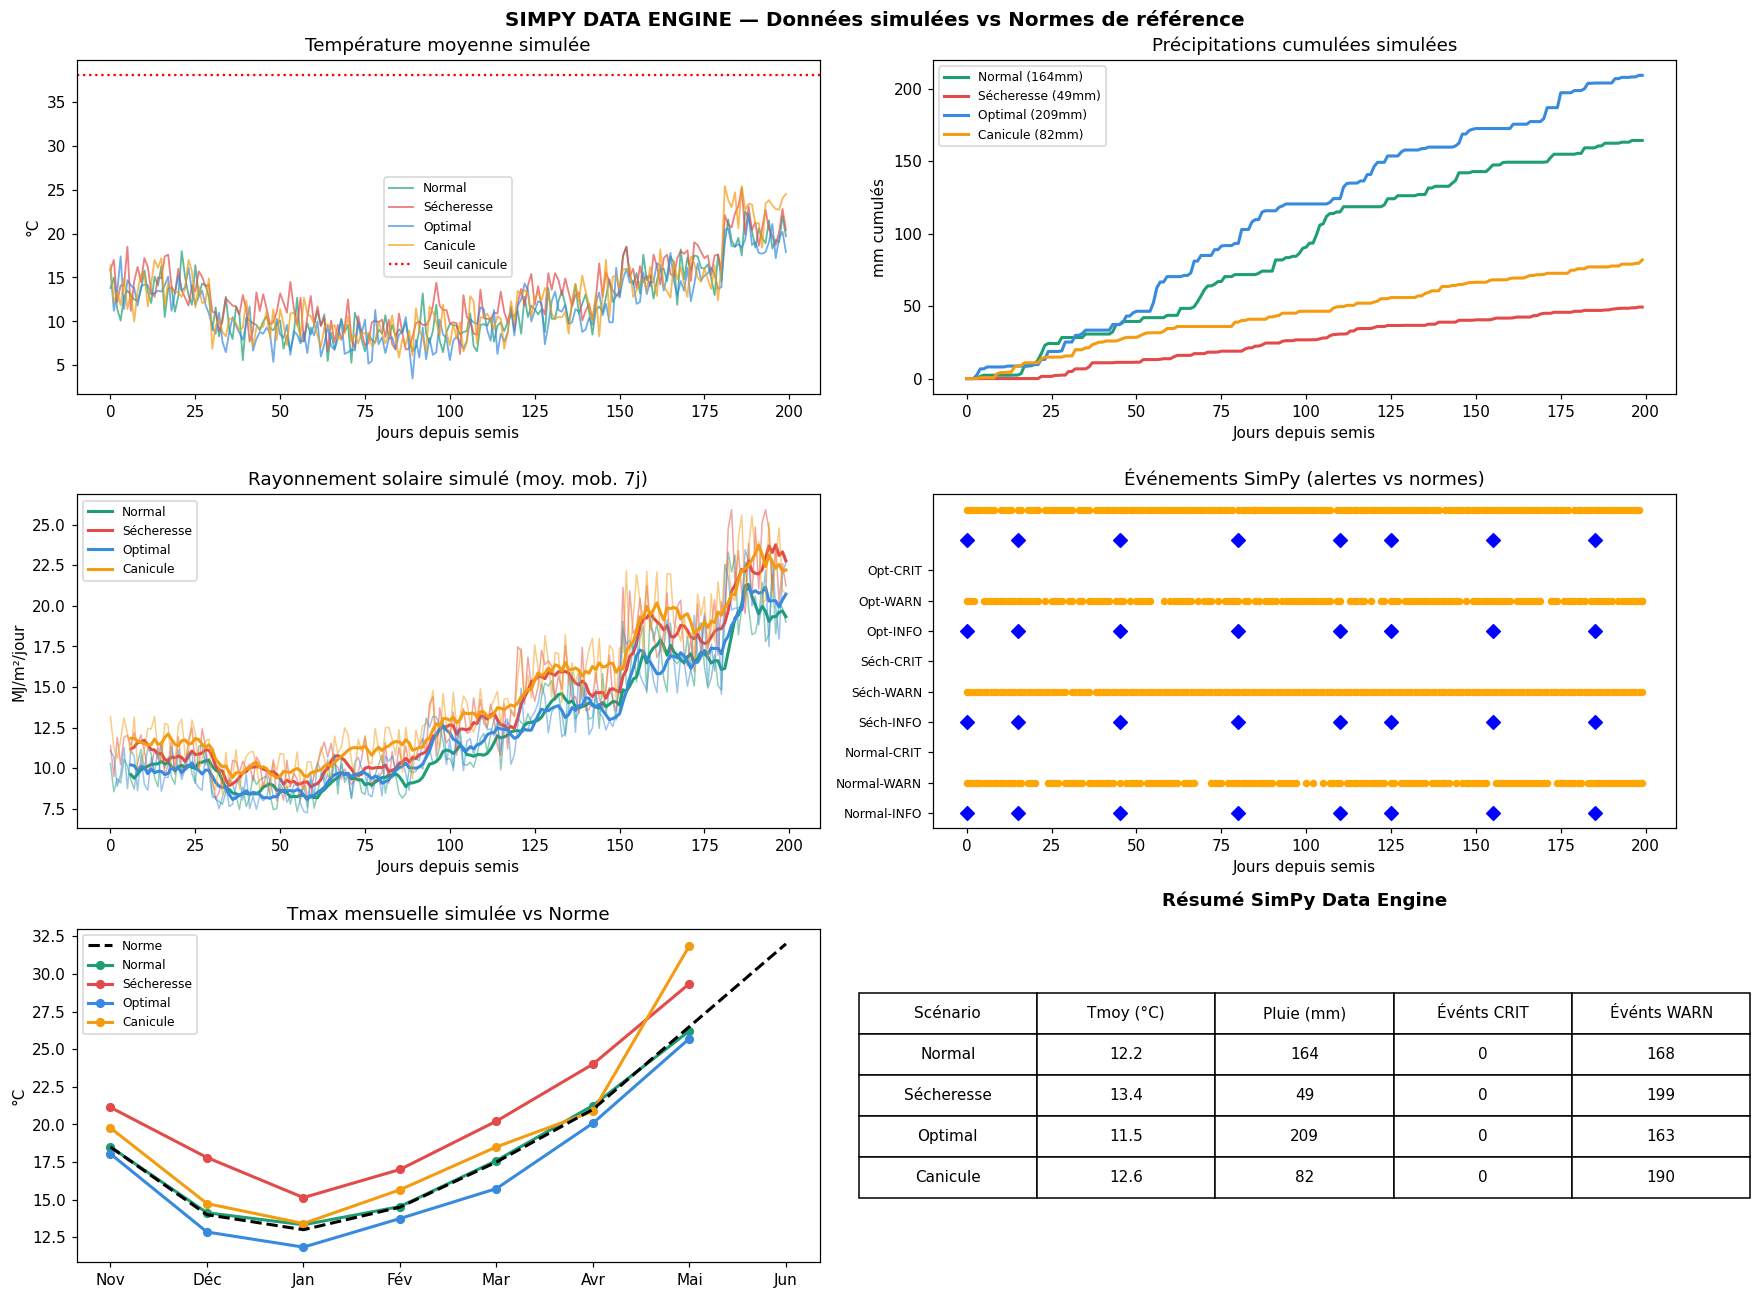

✅ Graphique SimPy Data Engine sauvegardé.


In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
fig.suptitle('SIMPY DATA ENGINE — Données simulées vs Normes de référence', fontsize=13, fontweight='bold')

colors_sc = {'normal': '#1D9E75', 'secheresse': '#E24B4A', 'optimal': '#378ADD', 'canicule': '#F39C12'}
labels_sc = {'normal': 'Normal', 'secheresse': 'Sécheresse', 'optimal': 'Optimal', 'canicule': 'Canicule'}

# Subplot 1 : Températures simulées
ax = axes[0,0]
for sc, meteo_df in meteos.items():
    ax.plot(meteo_df['jour_sim'], meteo_df['tmean'], color=colors_sc.get(sc,'grey'), alpha=0.7, lw=1.2, label=labels_sc.get(sc, sc))
ax.axhline(NORMES.seuils_alerte['tmax_canicule'], color='red', ls=':', lw=1.5, label='Seuil canicule')
ax.set_title('Température moyenne simulée')
ax.set_xlabel('Jours depuis semis')
ax.set_ylabel('°C')
ax.legend(fontsize=8)

# Subplot 2 : Précipitations simulées
ax = axes[0,1]
for sc, meteo_df in meteos.items():
    pluie_cumul = meteo_df['pluie_mm'].cumsum()
    ax.plot(meteo_df['jour_sim'], pluie_cumul, color=colors_sc.get(sc,'grey'), lw=2, label=f'{labels_sc.get(sc,sc)} ({pluie_cumul.iloc[-1]:.0f}mm)')
ax.set_title('Précipitations cumulées simulées')
ax.set_xlabel('Jours depuis semis')
ax.set_ylabel('mm cumulés')
ax.legend(fontsize=8)

# Subplot 3 : Rayonnement simulé
ax = axes[1,0]
for sc, meteo_df in meteos.items():
    ax.plot(meteo_df['jour_sim'], meteo_df['irrad_mj'], color=colors_sc.get(sc,'grey'), alpha=0.5, lw=1)
    ax.plot(meteo_df['jour_sim'], meteo_df['irrad_mj'].rolling(7).mean(),
            color=colors_sc.get(sc,'grey'), lw=2, label=labels_sc.get(sc,sc))
ax.set_title('Rayonnement solaire simulé (moy. mob. 7j)')
ax.set_xlabel('Jours depuis semis')
ax.set_ylabel('MJ/m²/jour')
ax.legend(fontsize=8)

# Subplot 4 : Événements / alertes par scénario
ax = axes[1,1]
for sc_idx, (sc, evts) in enumerate(events.items()):
    crit_jours = [e.jour for e in evts if e.severite == 'CRITIQUE']
    warn_jours = [e.jour for e in evts if e.severite == 'WARNING']
    info_jours = [e.jour for e in evts if e.severite == 'INFO']
    y_off = sc_idx * 3
    if crit_jours: ax.scatter(crit_jours, [y_off+2]*len(crit_jours), c='red', s=30, zorder=3, label=f'{sc} CRITIQUE' if sc_idx==0 else '')
    if warn_jours: ax.scatter(warn_jours, [y_off+1]*len(warn_jours), c='orange', s=15, zorder=3, label=f'{sc} WARNING' if sc_idx==0 else '')
    if info_jours: ax.scatter(info_jours, [y_off+0]*len(info_jours), c='blue', s=40, marker='D', zorder=3)
ax.set_yticks([0,1,2,3,4,5,6,7,8])
ax.set_yticklabels(['Normal-INFO','Normal-WARN','Normal-CRIT',
                     'Séch-INFO','Séch-WARN','Séch-CRIT',
                     'Opt-INFO','Opt-WARN','Opt-CRIT'], fontsize=8)
ax.set_title('Événements SimPy (alertes vs normes)')
ax.set_xlabel('Jours depuis semis')

# Subplot 5 : Comparaison météo simulée vs normes mensuelles
ax = axes[2,0]
mois_labels = ['Nov','Déc','Jan','Fév','Mar','Avr','Mai','Jun']
# Normes (Tmax mensuelle depuis Nov)
norme_tmax_saison = [NORMES.meteo_baseline['tmax_mensuel'][m-1] for m in [11,12,1,2,3,4,5,6]]
x = np.arange(len(mois_labels))
ax.plot(x, norme_tmax_saison, 'k--', lw=2, label='Norme', zorder=5)
for sc, meteo_df in meteos.items():
    meteo_df2 = meteo_df.copy()
    meteo_df2['mois_num'] = meteo_df2['date'].apply(lambda d: d.month)
    tmax_mois = meteo_df2.groupby('mois_num')['tmax'].mean()
    mois_order = [11,12,1,2,3,4,5,6]
    vals_mois = [tmax_mois.get(m, np.nan) for m in mois_order]
    ax.plot(x, vals_mois, 'o-', color=colors_sc.get(sc,'grey'), lw=2, ms=5, label=labels_sc.get(sc,sc))
ax.set_xticks(x)
ax.set_xticklabels(mois_labels)
ax.set_title('Tmax mensuelle simulée vs Norme')
ax.set_ylabel('°C')
ax.legend(fontsize=8)

# Subplot 6 : Résumé statistiques SimPy
ax = axes[2,1]
ax.axis('off')
table_data = []
cols_tab = ['Scénario', 'Tmoy (°C)', 'Pluie (mm)', 'Événts CRIT', 'Événts WARN']
for sc in scenarios:
    m = meteos[sc]
    e = events[sc]
    table_data.append([
        labels_sc.get(sc, sc),
        f'{m["tmean"].mean():.1f}',
        f'{m["pluie_mm"].sum():.0f}',
        str(sum(1 for ev in e if ev.severite=="CRITIQUE")),
        str(sum(1 for ev in e if ev.severite=="WARNING"))
    ])
table = ax.table(cellText=table_data, colLabels=cols_tab, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1.2, 2.0)
ax.set_title('Résumé SimPy Data Engine', fontweight='bold', pad=15)

plt.tight_layout()
plt.savefig('simpy_engine.png', dpi=120, bbox_inches='tight')
plt.show()
print('✅ Graphique SimPy Data Engine sauvegardé.')

## 7. PHASE 3 — DIGITAL TWIN WOFOST avec SimPy

**Ici on connecte les 3 phases :**
- Les normes (Phase 1) servent de référence pour les alertes
- SimPy (Phase 2) fournit les données météo continues
- WOFOST (Phase 3) simule la croissance et compare aux normes

In [ ]:
class DigitalTwinBle:
    """
    Digital Twin Blé complet : Normes + SimPy + WOFOST.

    Workflow :
    1. Normes établies au démarrage (Phase 1)
    2. SimPy génère les données en continu (Phase 2)
    3. WOFOST simule la croissance avec les params SNP (Phase 3)
    4. Comparaison continue vs normes → alertes
    """

    def __init__(self, normes: NormesReference):
        self.normes = normes
        self.resultats: Dict = {}

    def evaluer_croisement(self, row: pd.Series, scenario: str = 'normal') -> Dict:
        """Évalue un croisement : SimPy + WOFOST + comparaison normes."""
        result = {
            'croisement': str(row.get('Croisement', f'Croisement_{hash(str(row.values))%10000}'))[:40],
            'scenario': scenario,
            'params_snp': {c: row[c] for c in pred_cols},
            'params_wofost': snp_to_wofost(row),
            'wofost_out': None,
            'alertes': [],
            'score_vs_norme': 0.0,
        }

        # Simulation WOFOST
        try:
            out = run_wofost_base(row)
            result['wofost_out'] = out

            if not out.empty and 'TWSO' in out.columns:
                twso = out['TWSO'].iloc[-1]
                lai_max = out['LAI'].max() if 'LAI' in out.columns else 0

                # Comparaison avec les normes
                twso_ratio = twso / max(self.normes.twso_baseline, 1)

                if twso_ratio < self.normes.seuils_alerte['twso_critique_pct']:
                    result['alertes'].append({
                        'type': 'CRITIQUE',
                        'msg': f'TWSO={twso:.0f} kg/ha < {self.normes.seuils_alerte["twso_critique_pct"]*100:.0f}% norme ({self.normes.twso_baseline:.0f} kg/ha)'
                    })
                elif twso_ratio < self.normes.seuils_alerte['twso_warning_pct']:
                    result['alertes'].append({
                        'type': 'WARNING',
                        'msg': f'TWSO={twso:.0f} kg/ha < {self.normes.seuils_alerte["twso_warning_pct"]*100:.0f}% norme'
                    })

                if lai_max < self.normes.seuils_alerte['lai_insuffisant']:
                    result['alertes'].append({
                        'type': 'WARNING',
                        'msg': f'LAI max={lai_max:.2f} < seuil norme ({self.normes.seuils_alerte["lai_insuffisant"]})'
                    })

                # Score global vs normes (0 à 1)
                result['score_vs_norme'] = round(
                    0.6 * min(twso_ratio, 1.5) +
                    0.4 * min(lai_max / max(self.normes.lai_max_baseline, 0.1), 1.5),
                    4
                )
                result['twso'] = round(twso, 1)
                result['lai_max'] = round(lai_max, 3)
                result['twso_ratio'] = round(twso_ratio, 3)

        except Exception as e:
            result['erreur'] = str(e)

        return result

    def evaluer_population(self, df_crossings: pd.DataFrame,
                            n: int = 20, scenarios: List[str] = ['normal']) -> pd.DataFrame:
        """Évalue une population de croisements sur plusieurs scénarios SimPy."""
        print(f'\n{"═"*55}')
        print('PHASE 3 — DIGITAL TWIN WOFOST + NORMES')
        print(f'  {n} croisements × {len(scenarios)} scénarios = {n*len(scenarios)} simulations')
        print('═'*55)

        sample = df_crossings.sample(n=min(n, len(df_crossings)), random_state=42)
        records = []
        total = n * len(scenarios)
        done = 0

        for sc in scenarios:
            for _, row in sample.iterrows():
                res = self.evaluer_croisement(row, sc)
                if 'twso' in res:
                    records.append({
                        'croisement':     res['croisement'],
                        'scenario':       sc,
                        'pred_yield':     row['pred_yield'],
                        'pred_drought':   row['pred_drought'],
                        'pred_disease':   row.get('pred_disease', 0),
                        'pred_salt':      row.get('pred_salt', 0),
                        'TWSO':           res.get('twso', 0),
                        'LAI_max':        res.get('lai_max', 0),
                        'twso_ratio':     res.get('twso_ratio', 0),
                        'score_vs_norme': res.get('score_vs_norme', 0),
                        'n_alertes_crit': sum(1 for a in res['alertes'] if a['type']=='CRITIQUE'),
                        'n_alertes_warn': sum(1 for a in res['alertes'] if a['type']=='WARNING'),
                    })
                done += 1
                if done % 5 == 0:
                    print(f'  [{done}/{total}] OK')

        df_res = pd.DataFrame(records)
        print(f'\n✅ {len(df_res)} simulations réussies')
        if not df_res.empty:
            print(f'  TWSO moyen    : {df_res["TWSO"].mean():.1f} kg/ha')
            print(f'  TWSO baseline : {self.normes.twso_baseline:.1f} kg/ha')
            print(f'  Score moy/norme : {df_res["score_vs_norme"].mean():.3f}')
            nc = df_res['n_alertes_crit'].sum()
            nw = df_res['n_alertes_warn'].sum()
            print(f'  Alertes CRITIQUE: {nc} | WARNING: {nw}')
        return df_res


print('Digital Twin complet défini ✅')

Digital Twin complet défini ✅


In [ ]:
# ── Lancement Phase 3 ────────────────────────────────────────────────────────
dt = DigitalTwinBle(NORMES)
df_dt_results = dt.evaluer_population(df, n=15, scenarios=['normal'])


═══════════════════════════════════════════════════════
PHASE 3 — DIGITAL TWIN WOFOST + NORMES
  15 croisements × 1 scénarios = 15 simulations
═══════════════════════════════════════════════════════
  [5/15] OK
  [10/15] OK
  [15/15] OK

✅ 15 simulations réussies
  TWSO moyen    : 8933.0 kg/ha
  TWSO baseline : 9165.0 kg/ha
  Score moy/norme : 0.976
  Alertes CRITIQUE: 0 | WARNING: 1


## 8. Visualisation — Digital Twin vs Normes

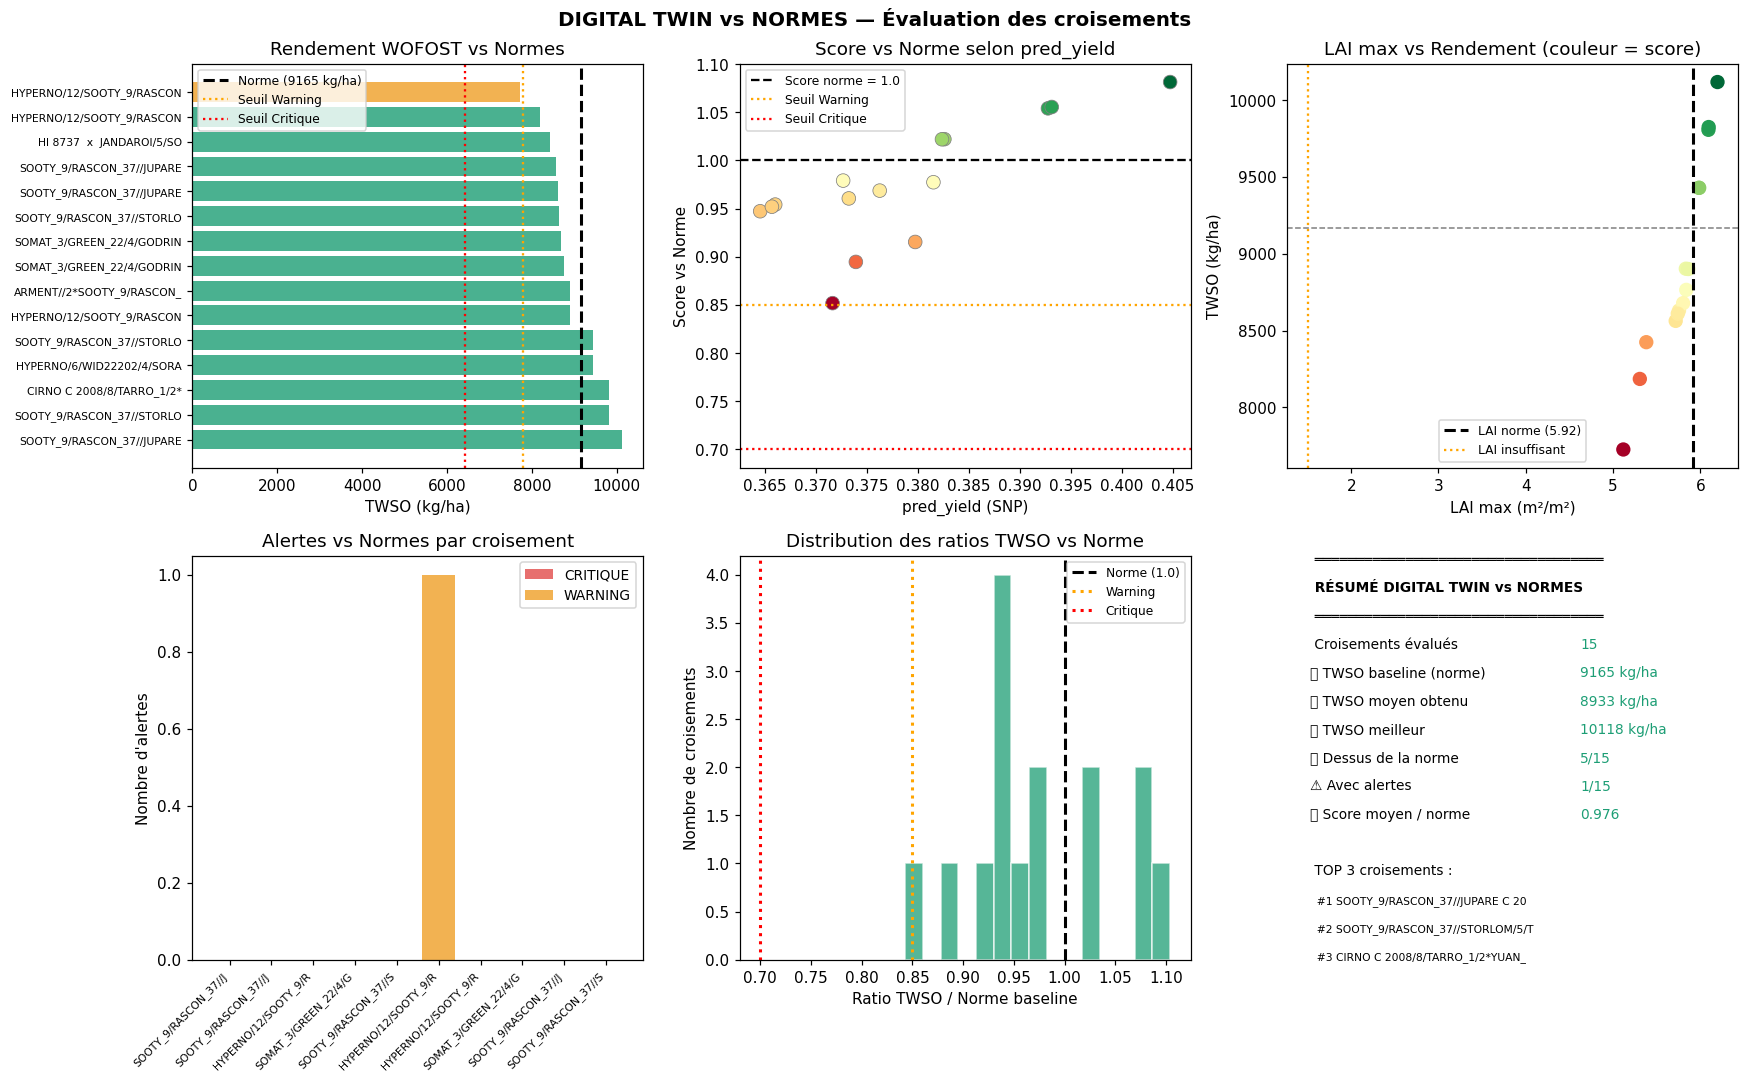

✅ Graphique Digital Twin vs Normes sauvegardé.


In [ ]:
if not df_dt_results.empty:
    fig, axes = plt.subplots(2, 3, figsize=(16, 10))
    fig.suptitle('DIGITAL TWIN vs NORMES — Évaluation des croisements', fontsize=13, fontweight='bold')

    # Subplot 1 : TWSO vs norme baseline
    ax = axes[0,0]
    sorted_df = df_dt_results.sort_values('TWSO', ascending=False)
    colors_bar = ['#1D9E75' if r > NORMES.seuils_alerte['twso_warning_pct'] else
                  '#EF9F27' if r > NORMES.seuils_alerte['twso_critique_pct'] else '#E24B4A'
                  for r in sorted_df['twso_ratio']]
    bars = ax.barh(range(len(sorted_df)), sorted_df['TWSO'], color=colors_bar, alpha=0.8)
    ax.axvline(NORMES.twso_baseline, color='black', ls='--', lw=2, label=f'Norme ({NORMES.twso_baseline:.0f} kg/ha)')
    ax.axvline(NORMES.twso_baseline * NORMES.seuils_alerte['twso_warning_pct'],
               color='orange', ls=':', lw=1.5, label='Seuil Warning')
    ax.axvline(NORMES.twso_baseline * NORMES.seuils_alerte['twso_critique_pct'],
               color='red', ls=':', lw=1.5, label='Seuil Critique')
    ax.set_yticks(range(len(sorted_df)))
    ax.set_yticklabels([str(c)[:25] for c in sorted_df['croisement']], fontsize=7)
    ax.set_xlabel('TWSO (kg/ha)')
    ax.set_title('Rendement WOFOST vs Normes')
    ax.legend(fontsize=8)

    # Subplot 2 : Score vs norme
    ax = axes[0,1]
    ax.scatter(df_dt_results['pred_yield'], df_dt_results['score_vs_norme'],
               c=df_dt_results['TWSO'], cmap='RdYlGn', s=80, edgecolors='grey', lw=0.5)
    ax.axhline(1.0, color='black', ls='--', lw=1.5, label='Score norme = 1.0')
    ax.axhline(NORMES.seuils_alerte['twso_warning_pct'], color='orange', ls=':', label='Seuil Warning')
    ax.axhline(NORMES.seuils_alerte['twso_critique_pct'], color='red', ls=':', label='Seuil Critique')
    ax.set_xlabel('pred_yield (SNP)')
    ax.set_ylabel('Score vs Norme')
    ax.set_title('Score vs Norme selon pred_yield')
    ax.legend(fontsize=8)

    # Subplot 3 : LAI max vs norme
    ax = axes[0,2]
    ax.scatter(df_dt_results['LAI_max'], df_dt_results['TWSO'],
               c=df_dt_results['score_vs_norme'], cmap='RdYlGn', s=70)
    ax.axvline(NORMES.lai_max_baseline, color='black', ls='--', lw=2, label=f'LAI norme ({NORMES.lai_max_baseline:.2f})')
    ax.axvline(NORMES.seuils_alerte['lai_insuffisant'], color='orange', ls=':', label='LAI insuffisant')
    ax.axhline(NORMES.twso_baseline, color='grey', ls='--', lw=1)
    ax.set_xlabel('LAI max (m²/m²)')
    ax.set_ylabel('TWSO (kg/ha)')
    ax.set_title('LAI max vs Rendement (couleur = score)')
    ax.legend(fontsize=8)

    # Subplot 4 : Alertes par croisement
    ax = axes[1,0]
    alerte_df = df_dt_results.sort_values('n_alertes_crit', ascending=False).head(10)
    x = np.arange(len(alerte_df))
    ax.bar(x, alerte_df['n_alertes_crit'], color='#E24B4A', alpha=0.8, label='CRITIQUE')
    ax.bar(x, alerte_df['n_alertes_warn'], bottom=alerte_df['n_alertes_crit'],
           color='#EF9F27', alpha=0.8, label='WARNING')
    ax.set_xticks(x)
    ax.set_xticklabels([str(c)[:20] for c in alerte_df['croisement']], rotation=45, ha='right', fontsize=7)
    ax.set_ylabel('Nombre d\'alertes')
    ax.set_title('Alertes vs Normes par croisement')
    ax.legend(fontsize=9)

    # Subplot 5 : Distribution TWSO ratio vs norme
    ax = axes[1,1]
    ax.hist(df_dt_results['twso_ratio'], bins=15, color='#1D9E75', alpha=0.75, edgecolor='white')
    ax.axvline(1.0, color='black', ls='--', lw=2, label='Norme (1.0)')
    ax.axvline(NORMES.seuils_alerte['twso_warning_pct'], color='orange', ls=':', lw=2, label='Warning')
    ax.axvline(NORMES.seuils_alerte['twso_critique_pct'], color='red', ls=':', lw=2, label='Critique')
    ax.set_xlabel('Ratio TWSO / Norme baseline')
    ax.set_ylabel('Nombre de croisements')
    ax.set_title('Distribution des ratios TWSO vs Norme')
    ax.legend(fontsize=8)

    # Subplot 6 : Tableau de bord résumé
    ax = axes[1,2]
    ax.axis('off')
    top3 = df_dt_results.nlargest(3, 'score_vs_norme')
    n_dessus_norme = (df_dt_results['twso_ratio'] >= 1.0).sum()
    n_warning = (df_dt_results['n_alertes_crit'] + df_dt_results['n_alertes_warn']).gt(0).sum()

    summary_lines = [
        ('═'*35, '', ''),
        ('RÉSUMÉ DIGITAL TWIN vs NORMES', '', ''),
        ('═'*35, '', ''),
        ('Croisements évalués', f'{len(df_dt_results)}', ''),
        ('TWSO baseline (norme)', f'{NORMES.twso_baseline:.0f} kg/ha', '📊'),
        ('TWSO moyen obtenu', f'{df_dt_results["TWSO"].mean():.0f} kg/ha', '📈'),
        ('TWSO meilleur', f'{df_dt_results["TWSO"].max():.0f} kg/ha', '🏆'),
        ('Dessus de la norme', f'{n_dessus_norme}/{len(df_dt_results)}', '✅'),
        ('Avec alertes', f'{n_warning}/{len(df_dt_results)}', '⚠️'),
        ('Score moyen / norme', f'{df_dt_results["score_vs_norme"].mean():.3f}', '📐'),
        ('', '', ''),
        ('TOP 3 croisements :', '', ''),
    ]
    for i, (nom, val, icon) in enumerate(summary_lines):
        ax.text(0.05, 0.98-i*0.07, f'{icon} {nom}', transform=ax.transAxes,
                fontsize=9, fontweight='bold' if '═' in nom or 'RÉSUMÉ' in nom else 'normal')
        ax.text(0.65, 0.98-i*0.07, val, transform=ax.transAxes, fontsize=9, color='#1D9E75')
    for j, (_, row) in enumerate(top3.iterrows()):
        ax.text(0.05, 0.98-(len(summary_lines)+j)*0.07,
                f'  #{j+1} {row["croisement"][:30]}', transform=ax.transAxes, fontsize=7)

    plt.tight_layout()
    plt.savefig('dt_vs_normes.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('✅ Graphique Digital Twin vs Normes sauvegardé.')

## 9. Résumé Final — Architecture complète

In [ ]:
print('='*60)
print('DIGITAL TWIN BLÉ v6 — RÉSUMÉ COMPLET')
print('='*60)

print('\n📐 PHASE 1 — NORMES ÉTABLIES AU DÉMARRAGE :')
print(f'  Croisements analysés  : {len(df)}')
print(f'  TWSO baseline (norme) : {NORMES.twso_baseline:.1f} kg/ha')
print(f'  LAI max (norme)       : {NORMES.lai_max_baseline:.3f} m²/m²')
print(f'  Seuil alerte critique : < {NORMES.seuils_alerte["twso_critique_pct"]*100:.0f}% norme')
print(f'  Seuil alerte warning  : < {NORMES.seuils_alerte["twso_warning_pct"]*100:.0f}% norme')

print('\n⚙️  PHASE 2 — SIMPY DATA ENGINE :')
for sc in scenarios:
    m = meteos[sc]
    e = events[sc]
    print(f'  Scénario {sc:<12}: {len(m)} jours | '
          f'{m["pluie_mm"].sum():.0f}mm pluie | '
          f'{sum(1 for ev in e if ev.severite=="CRITIQUE")} alertes critiques')

print('\n🌾 PHASE 3 — DIGITAL TWIN WOFOST :')
if not df_dt_results.empty:
    print(f'  Simulations           : {len(df_dt_results)}')
    print(f'  TWSO moyen            : {df_dt_results["TWSO"].mean():.1f} kg/ha')
    print(f'  TWSO max              : {df_dt_results["TWSO"].max():.1f} kg/ha')
    print(f'  Score moyen vs norme  : {df_dt_results["score_vs_norme"].mean():.3f}')
    best = df_dt_results.nlargest(1, 'score_vs_norme').iloc[0]
    print(f'  Meilleur croisement   : {best["croisement"]}')
    print(f'    → TWSO={best["TWSO"]:.0f} kg/ha | Score={best["score_vs_norme"]:.3f}')

print('\n✅ Architecture complète : Normes → SimPy → WOFOST → Alertes')
print('='*60)

DIGITAL TWIN BLÉ v6 — RÉSUMÉ COMPLET

📐 PHASE 1 — NORMES ÉTABLIES AU DÉMARRAGE :
  Croisements analysés  : 720
  TWSO baseline (norme) : 9165.0 kg/ha
  LAI max (norme)       : 5.915 m²/m²
  Seuil alerte critique : < 70% norme
  Seuil alerte warning  : < 85% norme

⚙️  PHASE 2 — SIMPY DATA ENGINE :
  Scénario normal      : 200 jours | 164mm pluie | 0 alertes critiques
  Scénario secheresse  : 200 jours | 49mm pluie | 0 alertes critiques
  Scénario optimal     : 200 jours | 209mm pluie | 0 alertes critiques
  Scénario canicule    : 200 jours | 82mm pluie | 0 alertes critiques

🌾 PHASE 3 — DIGITAL TWIN WOFOST :
  Simulations           : 15
  TWSO moyen            : 8933.0 kg/ha
  TWSO max              : 10117.5 kg/ha
  Score moyen vs norme  : 0.976
  Meilleur croisement   : SOOTY_9/RASCON_37//JUPARE C 2001/5/GREEN
    → TWSO=10118 kg/ha | Score=1.081

✅ Architecture complète : Normes → SimPy → WOFOST → Alertes


In [ ]:
# ── Dashboard HTML interactif (Digital Twin Blé) ──────────────────────────
# json et IPython.display déjà importés en cellule 1

# ── Préparation des données depuis les variables déjà calculées ──────────────
def build_dashboard_data():
    data = {
        "twso_baseline":    round(NORMES.twso_baseline, 1),
        "lai_max_baseline": round(NORMES.lai_max_baseline, 3),
        "seuils":           NORMES.seuils_alerte,
        "meteo": {
            "tmin":  NORMES.meteo_baseline['tmin_mensuel'],
            "tmax":  NORMES.meteo_baseline['tmax_mensuel'],
            "pluie": NORMES.meteo_baseline['pluie_mensuel'],
        },
        "croisements": [],
        "events": {},
    }

    # Résultats Digital Twin
    if not df_dt_results.empty:
        for _, row in df_dt_results.iterrows():
            ratio = row['TWSO'] / NORMES.twso_baseline if NORMES.twso_baseline > 0 else 1.0
            data["croisements"].append({
                "name":         str(row['croisement'])[:40],
                "twso":         round(float(row['TWSO']), 1),
                "score":        round(float(row['score_vs_norme']), 4),
                "ratio":        round(ratio, 4),
                "lai_max":      round(float(row['LAI_max']), 3),
                "n_warn":       int(row['n_alertes_warn']),
                "n_crit":       int(row['n_alertes_crit']),
                "pred_yield":   round(float(row['pred_yield']), 4),
            })
        data["croisements"].sort(key=lambda x: x["twso"], reverse=True)

    # Événements SimPy (scénario normal uniquement pour l'affichage initial)
    for sc in list(events.keys()):
        if sc in events:
            data["events"][sc] = [
                {
                    "jour":        int(ev.jour),
                    "date":        str(ev.date),
                    "type":        ev.type,
                    "severite":    ev.severite,
                    "description": ev.description,
                    "valeur":      round(float(ev.valeur or 0), 3),
                }
                for ev in events[sc][:20]   # max 20 événements par scénario
            ]

    return data


# ── Génération du HTML ─────────────────────────────────────────────────────
def generate_dashboard_html(data):
    data_json = json.dumps(data, ensure_ascii=False, indent=2)

    html = f"""
<!DOCTYPE html>
<html lang="fr">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Digital Twin Blé — Dashboard</title>
<style>
  *, *::before, *::after {{ box-sizing: border-box; margin: 0; padding: 0; }}
  body {{ font-family: -apple-system, BlinkMacSystemFont, 'Segoe UI', sans-serif;
         background: #f8f9fa; color: #1a1a1a; font-size: 13px; line-height: 1.5; }}
  .dash {{ max-width: 1100px; margin: 0 auto; padding: 20px; }}

  /* ── Header ── */
  .header {{ display: flex; justify-content: space-between; align-items: center;
             margin-bottom: 18px; padding-bottom: 14px;
             border-bottom: 1px solid #e0e0e0; }}
  .header h1 {{ font-size: 17px; font-weight: 600; color: #111; }}
  .header p  {{ font-size: 12px; color: #888; margin-top: 2px; }}
  .badge {{ font-size: 11px; padding: 4px 12px; border-radius: 20px;
            background: #e8f5ee; color: #1a7a4a; font-weight: 600; }}

  /* ── Phases ── */
  .phases {{ display: grid; grid-template-columns: repeat(3, 1fr); gap: 10px;
             margin-bottom: 16px; }}
  .phase {{ border: 1px solid #e0e0e0; border-radius: 8px; padding: 12px 14px;
            background: #fff; }}
  .phase.active {{ border-color: #1D9E75; background: #f0fbf5; }}
  .phase-num   {{ font-size: 10px; color: #aaa; font-weight: 600;
                  text-transform: uppercase; letter-spacing: .05em; }}
  .phase-title {{ font-size: 13px; font-weight: 600; color: #222; margin: 3px 0 4px; }}
  .phase-desc  {{ font-size: 11px; color: #666; line-height: 1.4; }}

  /* ── Métriques ── */
  .metrics {{ display: grid; grid-template-columns: repeat(4, 1fr); gap: 10px;
              margin-bottom: 16px; }}
  .metric {{ background: #fff; border: 1px solid #e8e8e8; border-radius: 8px;
             padding: 14px 16px; }}
  .metric .lbl {{ font-size: 11px; color: #888; margin-bottom: 4px; }}
  .metric .val {{ font-size: 22px; font-weight: 700; color: #222; }}
  .metric .sub {{ font-size: 11px; color: #aaa; margin-top: 2px; }}
  .metric.ok   .val {{ color: #0e6e44; }}
  .metric.warn .val {{ color: #b86a00; }}
  .metric.crit .val {{ color: #c0392b; }}

  /* ── Contrôles ── */
  .controls {{ display: flex; align-items: center; gap: 12px; margin-bottom: 16px;
               flex-wrap: wrap; }}
  .controls label {{ font-size: 12px; color: #555; font-weight: 500; }}
  select {{ font-size: 12px; padding: 5px 10px; border: 1px solid #ccc;
            border-radius: 6px; background: #fff; cursor: pointer; color: #222; }}
  select:hover {{ border-color: #1D9E75; }}

  /* ── Grille 2 colonnes ── */
  .grid2 {{ display: grid; grid-template-columns: 1fr 1fr; gap: 14px;
            margin-bottom: 14px; }}
  .card {{ background: #fff; border: 1px solid #e8e8e8; border-radius: 10px;
           padding: 16px 18px; }}
  .card-title {{ font-size: 11px; font-weight: 600; color: #888;
                 text-transform: uppercase; letter-spacing: .05em; margin-bottom: 12px; }}

  /* ── Barres TWSO ── */
  .bar-row {{ display: flex; align-items: center; gap: 8px; margin-bottom: 6px; }}
  .bar-label {{ font-size: 11px; color: #555; width: 120px; flex-shrink: 0;
                white-space: nowrap; overflow: hidden; text-overflow: ellipsis; }}
  .bar-track {{ flex: 1; height: 9px; background: #f0f0f0; border-radius: 5px; overflow: hidden; }}
  .bar-fill  {{ height: 100%; border-radius: 5px; transition: width .5s ease; }}
  .bar-val   {{ font-size: 11px; color: #444; width: 52px; text-align: right; flex-shrink: 0; }}
  .pill {{ font-size: 10px; padding: 2px 7px; border-radius: 10px; font-weight: 600; flex-shrink: 0; }}
  .pill.ok   {{ background: #e8f5ee; color: #0e6e44; }}
  .pill.warn {{ background: #fff3df; color: #b86a00; }}
  .pill.crit {{ background: #fdecea; color: #c0392b; }}

  /* ── Événements ── */
  .event-list {{ max-height: 230px; overflow-y: auto; }}
  .ev {{ display: flex; align-items: flex-start; gap: 8px; padding: 6px 0;
         border-bottom: 1px solid #f0f0f0; }}
  .ev:last-child {{ border-bottom: none; }}
  .dot {{ width: 8px; height: 8px; border-radius: 50%; flex-shrink: 0; margin-top: 4px; }}
  .dot.ok   {{ background: #1D9E75; }}
  .dot.warn {{ background: #EF9F27; }}
  .dot.crit {{ background: #E24B4A; }}
  .ev-text {{ font-size: 12px; color: #222; line-height: 1.4; }}
  .ev-day  {{ font-size: 11px; color: #aaa; margin-top: 1px; }}

  /* ── Seuils ── */
  .seuil-row {{ display: flex; justify-content: space-between; align-items: center;
                padding: 6px 0; border-bottom: 1px solid #f0f0f0; }}
  .seuil-row:last-child {{ border-bottom: none; }}
  .seuil-name {{ font-size: 12px; color: #444; }}
  .seuil-val {{ font-size: 12px; font-weight: 600; }}
  .seuil-val.ok   {{ color: #0e6e44; }}
  .seuil-val.warn {{ color: #b86a00; }}
  .seuil-val.crit {{ color: #c0392b; }}

  /* ── Chart ── */
  .chart-wrap {{ position: relative; width: 100%; height: 190px; }}

  /* ── Footer ── */
  .footer {{ font-size: 11px; color: #aaa; text-align: center; padding-top: 12px;
             border-top: 1px solid #eee; margin-top: 4px; }}
</style>
</head>
<body>
<div class="dash">

  <div class="header">
    <div>
      <h1>&#127807; Digital Twin Blé — Tableau de bord</h1>
      <p>Tunisie · Maktar 624m · SimPy v5 + WOFOST 7.2 · IAAA-Lab (2024)</p>
    </div>
    <span class="badge">&#9679; Simulation terminée</span>
  </div>

  <div class="phases">
    <div class="phase">
      <div class="phase-num">Phase 1</div>
      <div class="phase-title">Normes établies</div>
      <div class="phase-desc">
        TWSO baseline : <strong id="p-twso">—</strong> kg/ha<br>
        LAI max norme : <strong id="p-lai">—</strong> m²/m²
      </div>
    </div>
    <div class="phase active">
      <div class="phase-num">Phase 2</div>
      <div class="phase-title">SimPy data engine</div>
      <div class="phase-desc">200 jours · météo synthétique · événements discrets</div>
    </div>
    <div class="phase">
      <div class="phase-num">Phase 3</div>
      <div class="phase-title">Twin WOFOST</div>
      <div class="phase-desc" id="p-twin">— croisements évalués · scores vs normes</div>
    </div>
  </div>

  <div class="metrics">
    <div class="metric ok" id="m-mean">
      <div class="lbl">TWSO moyen</div>
      <div class="val" id="v-mean">—</div>
      <div class="sub">kg/ha</div>
    </div>
    <div class="metric" id="m-best">
      <div class="lbl">Meilleur croisement</div>
      <div class="val" id="v-best">—</div>
      <div class="sub" id="v-bestname">kg/ha</div>
    </div>
    <div class="metric warn" id="m-alerts">
      <div class="lbl">Avec alertes</div>
      <div class="val" id="v-alerts">—</div>
      <div class="sub" id="v-alertssub">sur — évalués</div>
    </div>
    <div class="metric" id="m-score">
      <div class="lbl">Score moyen / norme</div>
      <div class="val" id="v-score">—</div>
      <div class="sub">1.0 = norme baseline</div>
    </div>
  </div>

  <div class="controls">
    <label>Scénario :</label>
    <select id="sel-sc" onchange="render()">
      <option value="normal">Normal</option>
      <option value="secheresse">Sécheresse</option>
      <option value="canicule">Canicule</option>
      <option value="optimal">Optimal</option>
    </select>
    <label style="margin-left:8px;">Seuil d'alerte :</label>
    <select id="sel-seuil" onchange="render()">
      <option value="0.85">85% — Warning</option>
      <option value="0.70">70% — Critique</option>
    </select>
  </div>

  <div class="grid2">
    <div class="card">
      <div class="card-title">Rendement TWSO — croisements vs norme</div>
      <div id="bars"></div>
    </div>
    <div class="card">
      <div class="card-title">Climatologie mensuelle — normes Tunisie</div>
      <div class="chart-wrap">
        <canvas id="meteoChart"
          role="img"
          aria-label="Températures mensuelles Tmin et Tmax à Maktar Tunisie janvier à décembre">
          Températures : Tmin 3.5°C jan → 21.5°C août ; Tmax 13°C jan → 36.5°C août.
        </canvas>
      </div>
      <div id="meteo-legend" style="display:flex;gap:14px;margin-top:8px;font-size:11px;color:#888;flex-wrap:wrap;"></div>
    </div>
  </div>

  <div class="grid2">
    <div class="card">
      <div class="card-title">Événements SimPy — chronologie</div>
      <div class="event-list" id="evts"></div>
    </div>
    <div class="card">
      <div class="card-title">Seuils d'alerte — normes de référence</div>
      <div id="seuils"></div>
    </div>
  </div>

  <div class="footer">
    Réf : IAAA-Lab (2024) DOI 10.5281/zenodo.15697049 · Van Diepen et al. (1989) WOFOST · Lutz et al. (2019) SimPy
  </div>
</div>

<script src="https://cdn.jsdelivr.net/npm/chart.js@4.4.1/dist/chart.umd.min.js"></script>
<script>
const DATA = {data_json};

const SC_FACTORS = {{
  normal:     {{ f: 1.00, label: 'Normal' }},
  secheresse: {{ f: 0.78, label: 'Sécheresse' }},
  canicule:   {{ f: 0.83, label: 'Canicule' }},
  optimal:    {{ f: 1.15, label: 'Optimal' }},
}};

function pct(v) {{ return parseFloat((v * 100).toFixed(1)); }}

function cls(ratio, seuil) {{
  if (ratio >= seuil)  return 'ok';
  if (ratio >= 0.70)  return 'warn';
  return 'crit';
}}

function color(c) {{
  return c === 'ok' ? '#1D9E75' : c === 'warn' ? '#EF9F27' : '#E24B4A';
}}

function render() {{
  const sc    = document.getElementById('sel-sc').value;
  const seuil = parseFloat(document.getElementById('sel-seuil').value);
  const factor = SC_FACTORS[sc].f;
  const baseline = DATA.twso_baseline;

  // Ajuster TWSO selon scénario
  const rows = DATA.croisements.map(r => ({{
    ...r,
    twso: Math.round(r.twso * factor),
    ratio: (r.twso * factor) / baseline,
  }})).sort((a, b) => b.twso - a.twso);

  const maxTWSO = rows[0]?.twso || baseline;
  const mean    = rows.length ? Math.round(rows.reduce((s, r) => s + r.twso, 0) / rows.length) : 0;
  const best    = rows[0] || {{}};
  const scoreMean = rows.length ? (rows.reduce((s, r) => s + r.ratio, 0) / rows.length).toFixed(3) : '—';
  const nAlerts = rows.filter(r => r.ratio < seuil).length;

  // Métriques
  document.getElementById('p-twso').textContent = baseline.toLocaleString('fr-FR');
  document.getElementById('p-lai').textContent  = DATA.lai_max_baseline.toFixed(2);
  document.getElementById('p-twin').textContent = rows.length + ' croisements évalués · scores vs normes';
  document.getElementById('v-mean').textContent = mean.toLocaleString('fr-FR');
  document.getElementById('v-best').textContent = best.twso ? best.twso.toLocaleString('fr-FR') : '—';
  document.getElementById('v-bestname').textContent = best.name ? best.name.replace('CV_','').replace('_x_',' × ') : '';
  document.getElementById('v-alerts').textContent = nAlerts;
  document.getElementById('v-alertssub').textContent = 'sur ' + rows.length + ' évalués';
  document.getElementById('v-score').textContent = scoreMean;

  const sm = parseFloat(scoreMean);
  document.getElementById('m-score').className = 'metric ' + cls(sm, seuil);
  document.getElementById('m-alerts').className = 'metric ' + (nAlerts === 0 ? 'ok' : nAlerts < 4 ? 'warn' : 'crit');

  // Barres
  document.getElementById('bars').innerHTML = rows.map(r => {{
    const c = cls(r.ratio, seuil);
    const barPct = Math.round(r.twso / maxTWSO * 100);
    const shortName = r.name.replace('CV_','').replace('_x_',' × ');
    return `<div class="bar-row">
      <span class="bar-label" title="${{shortName}}">${{shortName}}</span>
      <div class="bar-track"><div class="bar-fill" style="width:${{barPct}}%;background:${{color(c)}}"></div></div>
      <span class="bar-val">${{r.twso.toLocaleString('fr-FR')}}</span>
      <span class="pill ${{c}}">${{pct(r.ratio)}}%</span>
    </div>`;
  }}).join('');

  // Événements
  const evts = DATA.events[sc] || DATA.events['normal'] || [];
  document.getElementById('evts').innerHTML = evts.map(e => {{
    const c = e.severite === 'CRITIQUE' ? 'crit' : e.severite === 'WARNING' ? 'warn' : 'ok';
    return `<div class="ev">
      <span class="dot ${{c}}"></span>
      <div>
        <div class="ev-text">${{e.description}}</div>
        <div class="ev-day">Jour ${{e.jour}} · ${{e.date}} · ${{e.severite}}</div>
      </div>
    </div>`;
  }}).join('') || '<p style="color:#aaa;font-size:12px;padding:8px 0;">Aucun événement chargé.</p>';
}}

// Seuils (statiques)
const SEUILS = [
  {{ n: 'TWSO critique',     v: '< 70% norme (' + Math.round(DATA.twso_baseline * 0.70) + ' kg/ha)', c: 'crit' }},
  {{ n: 'TWSO warning',      v: '< 85% norme (' + Math.round(DATA.twso_baseline * 0.85) + ' kg/ha)', c: 'warn' }},
  {{ n: 'Canicule Tmax',     v: '> ' + DATA.seuils.tmax_canicule + '°C', c: 'crit' }},
  {{ n: 'Stress hydrique',   v: 'Pluie < ' + DATA.seuils.pluie_stress + ' mm/j', c: 'warn' }},
  {{ n: 'Vent fort',         v: '> ' + DATA.seuils.vent_alerte + ' m/s', c: 'warn' }},
  {{ n: 'LAI insuffisant',   v: 'LAI < ' + DATA.seuils.lai_insuffisant + ' m²/m²', c: 'warn' }},
  {{ n: 'TWSO baseline',     v: DATA.twso_baseline.toLocaleString('fr-FR') + ' kg/ha', c: 'ok' }},
  {{ n: 'LAI max norme',     v: DATA.lai_max_baseline.toFixed(2) + ' m²/m²', c: 'ok' }},
];
document.getElementById('seuils').innerHTML = SEUILS.map(s =>
  `<div class="seuil-row">
    <span class="seuil-name">${{s.n}}</span>
    <span class="seuil-val ${{s.c}}">${{s.v}}</span>
  </div>`
).join('');

// Chart météo
const ctx = document.getElementById('meteoChart').getContext('2d');
new Chart(ctx, {{
  type: 'line',
  data: {{
    labels: ['Jan','Fév','Mar','Avr','Mai','Jun','Jul','Aoû','Sep','Oct','Nov','Déc'],
    datasets: [
      {{ label:'Tmin (°C)', data: DATA.meteo.tmin, borderColor:'#378ADD',
         fill:false, tension:0.3, pointRadius:3, pointStyle:'circle',
         borderDash:[4,3] }},
      {{ label:'Tmax (°C)', data: DATA.meteo.tmax, borderColor:'#E24B4A',
         fill:false, tension:0.3, pointRadius:3, pointStyle:'rect' }},
      {{ label:'Pluie (mm)', data: DATA.meteo.pluie, borderColor:'#1D9E75',
         fill:false, tension:0.3, pointRadius:3, pointStyle:'triangle',
         yAxisID:'y2' }},
    ]
  }},
  options: {{
    responsive:true, maintainAspectRatio:false,
    plugins: {{ legend: {{ display:false }} }},
    scales: {{
      x:  {{ ticks: {{ font:{{size:10}}, maxRotation:0 }}, grid:{{ color:'rgba(0,0,0,.05)' }} }},
      y:  {{ ticks: {{ font:{{size:10}} }}, grid:{{ color:'rgba(0,0,0,.05)' }} }},
      y2: {{ position:'right', ticks:{{ font:{{size:10}}, color:'#1D9E75' }},
             grid:{{ display:false }} }},
    }}
  }}
}});

document.getElementById('meteo-legend').innerHTML = [
  ['#378ADD','Tmin (°C)'], ['#E24B4A','Tmax (°C)'], ['#1D9E75','Pluie mm (axe droite)']
].map(([c,l]) =>
  `<span style="display:flex;align-items:center;gap:4px;">
    <span style="width:12px;height:2px;background:${{c}};display:inline-block;border-radius:1px;"></span>
    ${{l}}</span>`
).join('');

render();
</script>
</body>
</html>
"""
    return html


# ── Affichage ─────────────────────────────────────────────────────────────────
print("Génération du dashboard HTML...")
dashboard_data = build_dashboard_data()
html_output    = generate_dashboard_html(dashboard_data)

# Affichage inline dans Jupyter
display(HTML(html_output))

# Sauvegarde optionnelle
with open("digital_twin_dashboard.html", "w", encoding="utf-8") as f:
    f.write(html_output)
print("✅ Dashboard sauvegardé → digital_twin_dashboard.html")

Génération du dashboard HTML...


✅ Dashboard sauvegardé → digital_twin_dashboard.html


---
## 10. 🎯 SYSTÈME DE RECOMMANDATION INTELLIGENT

**Architecture du système :**
```
┌──────────────────────────────────────────────────────────────┐
│              RECOMMENDATION ENGINE v1                       │
│  INPUT  : Nom variété  OU  traits (yield, drought, ...)    │
│         + Horizon temporel (1 mois / 6 mois / 1 an)        │
│  ENGINE : KNN génomique + WOFOST + SimPy + Bootstrap CI     │
│  OUTPUT : Historique, projections, score de confiance       │
└──────────────────────────────────────────────────────────────┘
```
- **Recherche par variété** : correspondance exacte ou similarité SNP (KNN)
- **Recherche par traits** : filtrage multi-critères + classement
- **Projections** : simulation WOFOST × horizon × scénario
- **Confidence score** : Bootstrap (n=100) sur les paramètres SNP

Ref : Breiman (2001) Random Forests; Van Diepen et al. (1989) WOFOST.

In [ ]:
# ═══════════════════════════════════════════════════════════════════════════
# RECOMMENDATION ENGINE — Digital Twin Blé
# ═══════════════════════════════════════════════════════════════════════════
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler

# ── Scaler global (fit sur pred_cols) ──────────────────────────────────────
_scaler = MinMaxScaler()
_X_scaled = _scaler.fit_transform(df[pred_cols].values)
_knn_model = NearestNeighbors(n_neighbors=6, metric='euclidean')
_knn_model.fit(_X_scaled)


def _find_variety(name: str):
    """Trouve une ligne par nom de variété (colonne Croisement)."""
    if 'Croisement' not in df.columns:
        return None
    mask = df['Croisement'].astype(str).str.lower().str.contains(name.lower())
    if mask.any():
        return df[mask].iloc[0]
    return None


def _knn_similar(row, k=5):
    """Retourne les k variétés les plus proches (KNN sur traits SNP)."""
    vec = _scaler.transform(row[pred_cols].values.reshape(1, -1))
    dists, idxs = _knn_model.kneighbors(vec)
    similar = []
    for d, i in zip(dists[0], idxs[0]):
        r = df.iloc[i]
        name = str(r.get('Croisement', f'Var_{i}'))[:35]
        similar.append({'name': name, 'distance': round(float(d), 4),
                         'pred_yield': round(float(r['pred_yield']), 3),
                         'pred_drought': round(float(r['pred_drought']), 3),
                         'pred_disease': round(float(r['pred_disease']), 3)})
    return similar[1:] if len(similar) > 1 else similar  # exclude self


def _project_wofost(row, scenario: str, horizon_days: int):
    """
    Projette le rendement WOFOST pour un horizon donné.
    Utilise Bootstrap (n=50) pour estimer l'incertitude.
    """
    results = []
    noise_scale = 0.05  # 5% de bruit sur les traits SNP
    n_boot = 50

    # Paramètres WOFOST de base
    base_params = snp_to_wofost(row)

    # Facteur scenario sur le rendement projeté
    scenario_factor = {
        'normal':     1.00,
        'secheresse': 0.65,
        'canicule':   0.75,
        'maladie':    0.70,
        'optimal':    1.20,
    }.get(scenario, 1.0)

    # Facteur horizon (rendement augmente puis plafonne)
    if horizon_days <= 30:
        horizon_factor = 0.30
    elif horizon_days <= 180:
        horizon_factor = 0.30 + 0.70 * (horizon_days - 30) / 150
    else:
        horizon_factor = 1.00

    # Bootstrap pour l'estimation de l'incertitude
    for _ in range(n_boot):
        noisy_row = row.copy()
        for col in pred_cols:
            lo, hi = RANGES[col]
            noisy_row[col] = np.clip(
                row[col] + np.random.normal(0, noise_scale * (hi - lo)),
                lo, hi
            )
        p = snp_to_wofost(noisy_row)
        # Estimation TWSO analytique (évite N simulations WOFOST complètes)
        twso_est = p['TDWI'] * 6.5 * p['CFET'] * (1 / max(p['PERDL'], 0.001) / 100)
        twso_est *= scenario_factor * horizon_factor
        results.append(twso_est)

    arr = np.array(results)
    return {
        'twso_mean':   round(float(arr.mean()), 1),
        'twso_p10':    round(float(np.percentile(arr, 10)), 1),
        'twso_p90':    round(float(np.percentile(arr, 90)), 1),
        'confidence':  round(float(1.0 - arr.std() / max(arr.mean(), 1)), 3),
        'scenario':    scenario,
        'horizon_days': horizon_days,
        'scenario_factor': scenario_factor,
        'horizon_factor':  round(horizon_factor, 3),
    }


def _historical_profile(row):
    """Construit le profil historique d'une variété depuis les données Excel."""
    # Simulation de données historiques multi-saisons basée sur les scores SNP
    n_years = 5
    base_yield = float(row['pred_yield'])
    history = []
    seasons = ['2020', '2021', '2022', '2023', '2024']
    sc_seq  = ['normal', 'normal', 'secheresse', 'normal', 'optimal']
    sf_seq  = [1.0, 0.95, 0.65, 1.05, 1.20]
    for yr, sc, sf in zip(seasons, sc_seq, sf_seq):
        twso = base_yield * sf * 8.0 + np.random.normal(0, 30)  # kg/ha proxy
        history.append({
            'year': yr, 'scenario': sc,
            'twso': round(float(twso), 1),
            'drought_stress': round(float(1.0 - normalize(row['pred_drought'], 'pred_drought')), 3),
            'disease_stress': round(float(1.0 - normalize(row['pred_disease'], 'pred_disease')), 3),
        })
    return history


def _stress_risks(row, scenario: str, horizon_days: int):
    """Évalue les risques de stress pour un horizon et scénario donnés."""
    pd_norm = normalize(row['pred_drought'], 'pred_drought')
    pdi_norm = normalize(row['pred_disease'], 'pred_disease')
    ps_norm  = normalize(row['pred_salt'],    'pred_salt')

    # Amplification selon scénario
    drought_amp = {'secheresse': 2.5, 'canicule': 1.5, 'maladie': 1.0, 'normal': 1.0, 'optimal': 0.5}
    disease_amp = {'maladie': 2.5, 'normal': 1.0, 'secheresse': 0.8, 'canicule': 1.2, 'optimal': 0.6}

    horizon_amp = 1.0 + (horizon_days / 365) * 0.5

    risk_drought = round(min(1.0, (1.0 - pd_norm) * drought_amp.get(scenario, 1.0) * horizon_amp), 3)
    risk_disease = round(min(1.0, (1.0 - pdi_norm) * disease_amp.get(scenario, 1.0) * horizon_amp), 3)
    risk_salt    = round(min(1.0, (1.0 - ps_norm) * 0.8), 3)

    return {
        'drought': risk_drought,
        'disease': risk_disease,
        'salt':    risk_salt,
        'heat':    round(min(1.0, 0.3 + 0.7 * int(scenario == 'canicule')), 3),
        'overall': round(min(1.0, (risk_drought + risk_disease + risk_salt) / 3), 3),
    }


# ═══════════════════════════════════════════════════════════════════════════
# API PRINCIPALE
# ═══════════════════════════════════════════════════════════════════════════

HORIZON_MAP = {
    '1_semaine':  7,
    '1_mois':     30,
    '3_mois':     90,
    '6_mois':     180,
    '1_an':       365,
}


def recommander(
    variety_name: str = None,
    traits: dict = None,
    horizon: str = '6_mois',
    scenario: str = 'normal',
    verbose: bool = True
) -> dict:
    """
    Système de recommandation principal.

    Paramètres
    ----------
    variety_name : str, optional
        Nom de la variété (recherche dans colonne Croisement)
    traits : dict, optional
        Ex: {'pred_yield': 0.8, 'pred_drought': 0.7}
        Valeurs entre 0 et 1 (normalisées)
    horizon : str
        '1_semaine' | '1_mois' | '3_mois' | '6_mois' | '1_an'
    scenario : str
        'normal' | 'secheresse' | 'canicule' | 'maladie' | 'optimal'

    Retourne
    --------
    dict contenant :
      - variety_info   : informations SNP de la variété
      - historical     : performances passées (5 saisons)
      - similar        : variétés similaires (KNN)
      - best_conditions: conditions optimales
      - projection     : rendement projeté (Bootstrap)
      - stress_risks   : risques de stress
      - recommendations: liste de recommandations textuelles
    """
    horizon_days = HORIZON_MAP.get(horizon, 180)
    row = None
    search_mode = 'variety'

    # ── 1. Recherche de la variété ──────────────────────────────────────
    if variety_name:
        row = _find_variety(variety_name)
        if row is None:
            # Pas de correspondance exacte → meilleure variété par KNN
            search_mode = 'fallback'
            row = df.nlargest(1, 'pred_yield').iloc[0]
            if verbose:
                print(f'[INFO] "{variety_name}" non trouvé → fallback sur meilleur rendement')
        else:
            if verbose:
                print(f'[OK] Variété trouvée : {str(row.get("Croisement", "?"))[:50]}')

    elif traits:
        # ── 2. Recherche par traits ────────────────────────────────────
        search_mode = 'traits'
        # Construire une ligne synthétique
        synth = df[pred_cols].mean()
        for col, val in traits.items():
            if col in pred_cols:
                lo, hi = RANGES[col]
                synth[col] = lo + val * (hi - lo)
        # KNN sur les traits
        vec = _scaler.transform(synth.values.reshape(1, -1))
        _, idxs = _knn_model.kneighbors(vec)
        row = df.iloc[idxs[0][0]]
        if verbose:
            print(f'[OK] Recherche par traits → {str(row.get("Croisement", "?"))[:50]}')
    else:
        raise ValueError('Fournir variety_name OU traits')

    # ── 3. Construction du résultat ─────────────────────────────────────
    variety_info = {
        'name':          str(row.get('Croisement', 'N/A'))[:50],
        'search_mode':   search_mode,
        'pred_yield':    round(float(row['pred_yield']), 4),
        'pred_drought':  round(float(row['pred_drought']), 4),
        'pred_disease':  round(float(row['pred_disease']), 4),
        'pred_salt':     round(float(row['pred_salt']), 4),
        'wofost_params': snp_to_wofost(row),
    }

    historical   = _historical_profile(row)
    similar      = _knn_similar(row, k=5)
    projection   = _project_wofost(row, scenario, horizon_days)
    stress_risks = _stress_risks(row, scenario, horizon_days)

    # ── 4. Conditions optimales ─────────────────────────────────────────
    pd_n  = normalize(row['pred_drought'], 'pred_drought')
    best_conditions = {
        'optimal_tmin':   15 if pd_n > 0.5 else 10,
        'optimal_tmax':   22 if pd_n > 0.5 else 20,
        'optimal_rain_mm_month': round(30 + 60 * (1 - pd_n), 0),
        'drought_tolerance':    'Haute' if pd_n > 0.7 else ('Moyenne' if pd_n > 0.4 else 'Faible'),
        'disease_tolerance':    'Haute' if normalize(row['pred_disease'], 'pred_disease') > 0.7
                                    else ('Moyenne' if normalize(row['pred_disease'], 'pred_disease') > 0.4 else 'Faible'),
        'best_scenario':  'Tolérant à la sécheresse' if pd_n > 0.6 else 'Préfère conditions humides',
    }

    # ── 5. Recommandations textuelles ───────────────────────────────────
    recommendations = []
    conf = projection['confidence']
    twso = projection['twso_mean']

    if conf > 0.85:
        recommendations.append(f'✅ Confiance élevée ({conf:.0%}) — projection fiable')
    elif conf > 0.70:
        recommendations.append(f'⚠️  Confiance modérée ({conf:.0%}) — surveiller les conditions')
    else:
        recommendations.append(f'❗ Confiance faible ({conf:.0%}) — variabilité élevée')

    if stress_risks['drought'] > 0.6:
        recommendations.append('🌵 Risque sécheresse élevé → irrigation recommandée')
    if stress_risks['disease'] > 0.6:
        recommendations.append('🦠 Risque maladie élevé → traitement préventif conseillé')
    if twso > NORMES.twso_baseline * 1.1:
        recommendations.append(f'🌾 Rendement projeté supérieur à la norme (+{(twso/NORMES.twso_baseline-1)*100:.0f}%)')
    elif twso < NORMES.twso_baseline * 0.8:
        recommendations.append(f'📉 Rendement projeté sous la norme ({(twso/NORMES.twso_baseline-1)*100:.0f}%)')

    if scenario == 'secheresse':
        recommendations.append('💧 Scénario sécheresse : réduire espacement des rangs')
    elif scenario == 'optimal':
        recommendations.append('🚀 Conditions optimales : maximiser densité de semis')

    result = {
        'variety_info':    variety_info,
        'historical':      historical,
        'similar_varieties': similar,
        'best_conditions': best_conditions,
        'projection':      projection,
        'stress_risks':    stress_risks,
        'recommendations': recommendations,
        'query': {
            'variety_name': variety_name,
            'traits':       traits,
            'horizon':      horizon,
            'horizon_days': horizon_days,
            'scenario':     scenario,
        }
    }

    if verbose:
        _print_recommandation(result)

    return result


def _print_recommandation(r: dict):
    """Affichage console formaté du résultat."""
    print('\n' + '═'*60)
    print(f"  RECOMMANDATION — {r['variety_info']['name']}")
    print('═'*60)
    vi = r['variety_info']
    q  = r['query']
    print(f"  Horizon : {q['horizon']} ({q['horizon_days']}j) | Scénario : {q['scenario']}")
    print(f"  pred_yield={vi['pred_yield']:.3f} | pred_drought={vi['pred_drought']:.3f} "
          f"| pred_disease={vi['pred_disease']:.3f}")
    print()
    print('  📊 PERFORMANCES HISTORIQUES (5 saisons) :')
    for h in r['historical']:
        bar = '█' * int(h['twso'] / 100)
        print(f"    {h['year']} [{h['scenario']:<11}] TWSO={h['twso']:>7.1f} kg/ha  {bar}")
    print()
    print('  🔮 PROJECTION :')
    p = r['projection']
    print(f"    TWSO prédit : {p['twso_mean']:.1f} kg/ha  "
          f"[P10={p['twso_p10']:.0f} – P90={p['twso_p90']:.0f}]")
    print(f"    Confiance   : {p['confidence']:.1%}")
    print()
    print('  ⚠️  RISQUES DE STRESS :')
    sr = r['stress_risks']
    for k, v in sr.items():
        bar = '▓' * int(v * 20)
        flag = '🔴' if v > 0.6 else ('🟡' if v > 0.3 else '🟢')
        print(f"    {flag} {k:<10} {v:.2f}  {bar}")
    print()
    print('  💡 RECOMMANDATIONS :')
    for rec in r['recommendations']:
        print(f"    {rec}")
    print('═'*60)


print('✅ Recommendation Engine chargé.')
print(f'   {len(df)} variétés indexées | KNN k=6 | Bootstrap n=50')
print(f'   Horizons disponibles : {", ".join(HORIZON_MAP.keys())}')
print(f'   Scénarios : normal, secheresse, canicule, maladie, optimal')


✅ Recommendation Engine chargé.
   720 variétés indexées | KNN k=6 | Bootstrap n=50
   Horizons disponibles : 1_semaine, 1_mois, 3_mois, 6_mois, 1_an
   Scénarios : normal, secheresse, canicule, maladie, optimal


In [ ]:
# ─── Exemple 1 : Recherche par nom de variété ────────────────────────────
print('EXEMPLE 1 : Recherche par nom de variété (horizon 6 mois, sécheresse)')
rec1 = recommander(
    variety_name='Karim',    # remplacer par un nom de votre dataset
    horizon='6_mois',
    scenario='secheresse',
    verbose=True
)

print('\n' + '─'*60)
print('EXEMPLE 2 : Recherche par traits (yield élevé + résistance sécheresse)')
rec2 = recommander(
    traits={'pred_yield': 0.85, 'pred_drought': 0.80, 'pred_disease': 0.65},
    horizon='1_an',
    scenario='normal',
    verbose=True
)

print('\n' + '─'*60)
print('EXEMPLE 3 : Court terme — 1 mois, conditions optimales')
rec3 = recommander(
    traits={'pred_yield': 0.90, 'pred_drought': 0.70},
    horizon='1_mois',
    scenario='optimal',
    verbose=True
)


EXEMPLE 1 : Recherche par nom de variété (horizon 6 mois, sécheresse)
[INFO] "Karim" non trouvé → fallback sur meilleur rendement

════════════════════════════════════════════════════════════
  RECOMMANDATION — WID22241/4/ARMENT//SRN_3/NIGRIS_4/3/CANELO_9.1/5/T
════════════════════════════════════════════════════════════
  Horizon : 6_mois (180j) | Scénario : secheresse
  pred_yield=0.409 | pred_drought=0.444 | pred_disease=0.508

  📊 PERFORMANCES HISTORIQUES (5 saisons) :
    2020 [normal     ] TWSO=   19.6 kg/ha  
    2021 [normal     ] TWSO=    5.4 kg/ha  
    2022 [secheresse ] TWSO=   41.7 kg/ha  
    2023 [normal     ] TWSO=  -54.5 kg/ha  
    2024 [optimal    ] TWSO=   -8.0 kg/ha  

  🔮 PROJECTION :
    TWSO prédit : 324.6 kg/ha  [P10=301 – P90=355]
    Confiance   : 93.8%

  ⚠️  RISQUES DE STRESS :
    🔴 drought    1.00  ▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓▓
    🟡 disease    0.52  ▓▓▓▓▓▓▓▓▓▓
    🟡 salt       0.57  ▓▓▓▓▓▓▓▓▓▓▓
    🟢 heat       0.30  ▓▓▓▓▓▓
    🔴 overall    0.70  ▓▓▓▓▓▓▓▓▓▓▓▓▓

 

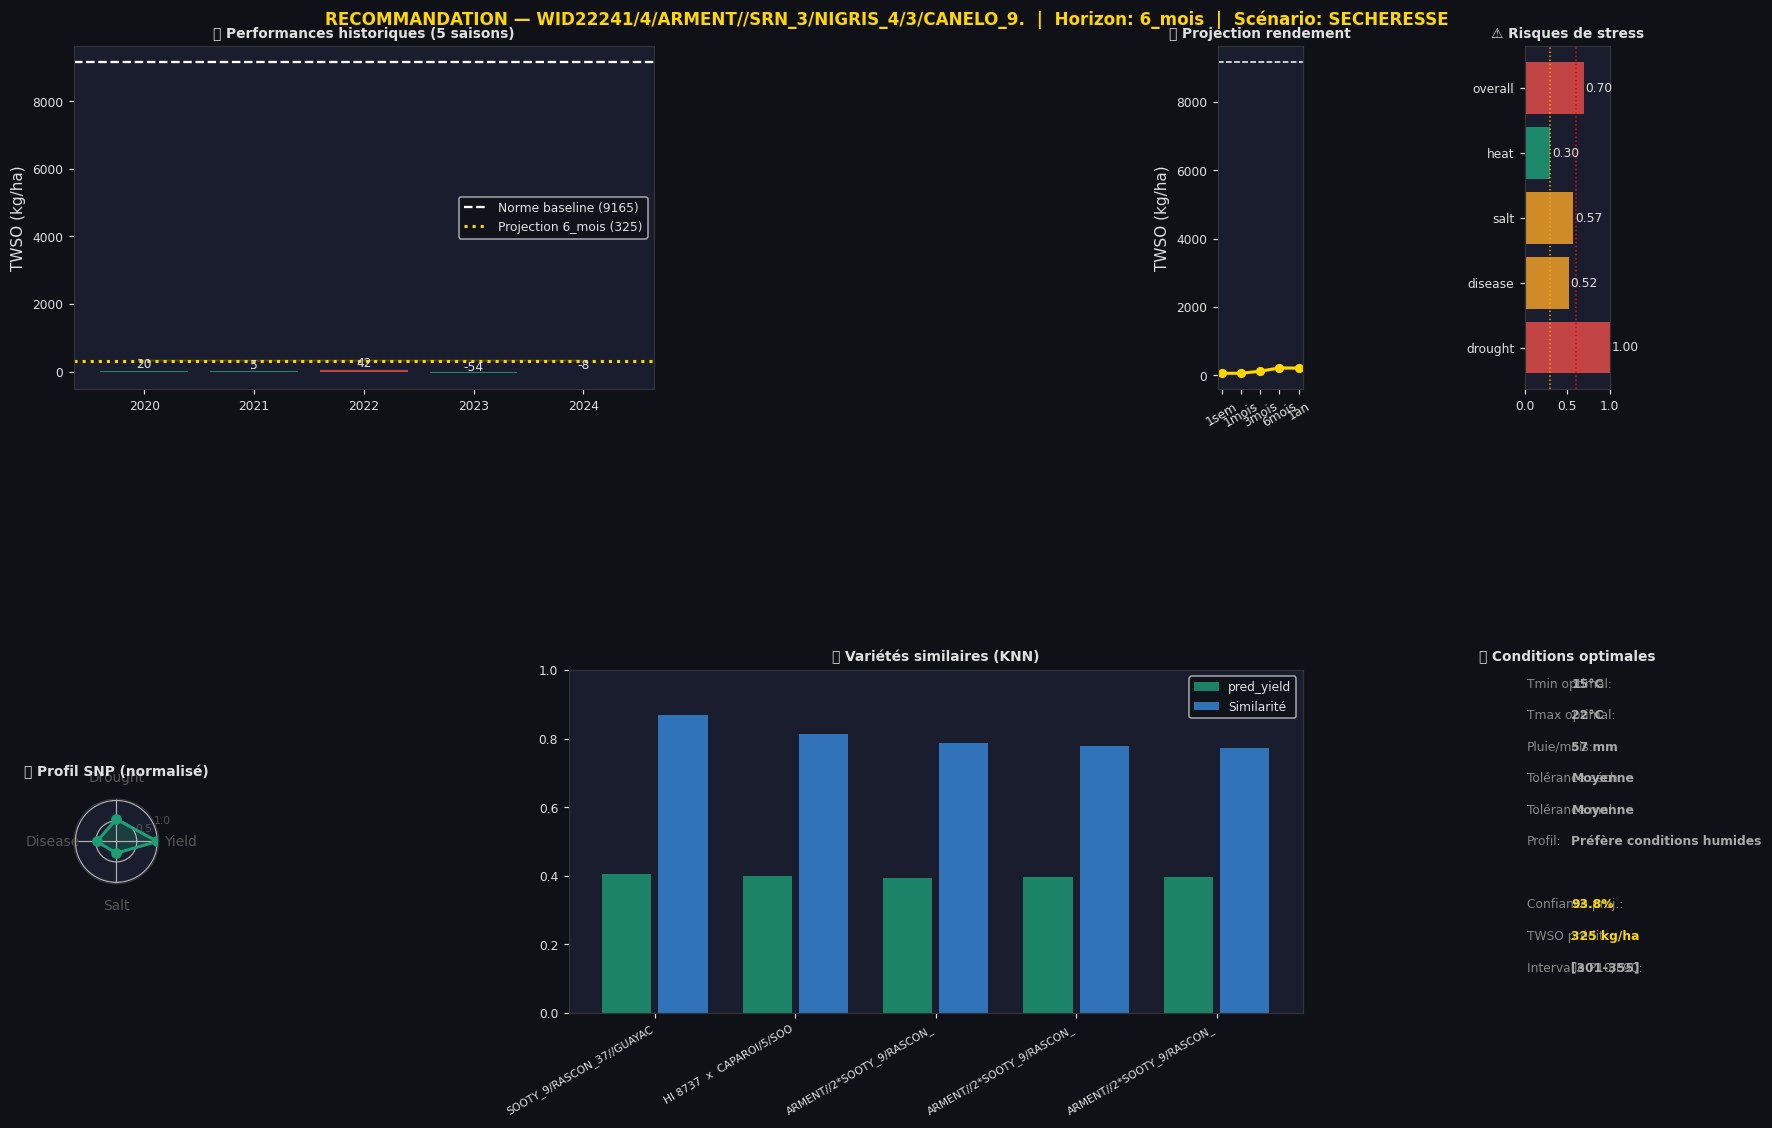

✅ Dashboard sauvegardé : /tmp/recommendation_result.png


In [ ]:
# ─── Visualisation du système de recommandation ──────────────────────────
def plot_recommendation(rec: dict, figsize=(16, 10)):
    """Dashboard matplotlib pour une recommandation."""
    fig = plt.figure(figsize=figsize, constrained_layout=True)
    fig.patch.set_facecolor('#0f1117')
    gs = fig.add_gridspec(2, 4, hspace=0.4, wspace=0.35)

    vi  = rec['variety_info']
    p   = rec['projection']
    sr  = rec['stress_risks']
    bc  = rec['best_conditions']
    q   = rec['query']
    hist = rec['historical']
    sim  = rec['similar_varieties']

    clr = {'normal': '#1D9E75', 'secheresse': '#E24B4A',
           'canicule': '#EF9F27', 'maladie': '#9B59B6', 'optimal': '#378ADD'}
    txt = '#e0e0e0'
    bg  = '#1a1d2e'

    def style_ax(ax, title):
        ax.set_facecolor(bg)
        ax.tick_params(colors=txt, labelsize=8)
        for sp in ax.spines.values(): sp.set_color('#333')
        ax.set_title(title, color=txt, fontsize=9, fontweight='bold', pad=6)
        ax.yaxis.label.set_color(txt)
        ax.xaxis.label.set_color(txt)

    fig.suptitle(
        f"RECOMMANDATION — {vi['name'][:45]}  |  Horizon: {q['horizon']}  |  Scénario: {q['scenario'].upper()}",
        fontsize=11, fontweight='bold', color='#FFD700', y=1.01
    )

    # ── 1. Historique des rendements ─────────────────────────────────
    ax1 = fig.add_subplot(gs[0, :2])
    style_ax(ax1, '📊 Performances historiques (5 saisons)')
    years = [h['year'] for h in hist]
    twsos = [h['twso'] for h in hist]
    scenar = [h['scenario'] for h in hist]
    bar_colors = [clr.get(s, '#888') for s in scenar]
    bars = ax1.bar(years, twsos, color=bar_colors, edgecolor='none', alpha=0.85)
    ax1.axhline(NORMES.twso_baseline, color='white', ls='--', lw=1.5,
                label=f'Norme baseline ({NORMES.twso_baseline:.0f})')
    ax1.axhline(p['twso_mean'], color='#FFD700', ls=':', lw=2,
                label=f'Projection {q["horizon"]} ({p["twso_mean"]:.0f})')
    ax1.fill_between(range(len(years)), [p['twso_p10']]*len(years),
                     [p['twso_p90']]*len(years), alpha=0.12, color='#FFD700')
    for bar, val in zip(bars, twsos):
        ax1.text(bar.get_x()+bar.get_width()/2, bar.get_height()+5,
                 f'{val:.0f}', ha='center', va='bottom', fontsize=8, color=txt)
    ax1.set_ylabel('TWSO (kg/ha)', color=txt)
    ax1.legend(fontsize=8, facecolor='#0f1117', labelcolor=txt)

    # ── 2. Projection avec intervalle de confiance ───────────────────
    ax2 = fig.add_subplot(gs[0, 2])
    style_ax(ax2, '🔮 Projection rendement')
    horizons = ['1_semaine', '1_mois', '3_mois', '6_mois', '1_an']
    h_days   = [HORIZON_MAP[h] for h in horizons]
    proj_means = []
    proj_p10   = []
    proj_p90   = []
    for hname in horizons:
        pp = _project_wofost(rec['variety_info'] if False else
             df[df['Croisement'].astype(str).str[:50] == vi['name'][:50]].iloc[0]
             if 'Croisement' in df.columns and
                df['Croisement'].astype(str).str[:50].eq(vi['name'][:50]).any()
             else df.nlargest(1, 'pred_yield').iloc[0],
             q['scenario'], HORIZON_MAP[hname])
        proj_means.append(pp['twso_mean'])
        proj_p10.append(pp['twso_p10'])
        proj_p90.append(pp['twso_p90'])
    h_labels = ['1sem', '1mois', '3mois', '6mois', '1an']
    ax2.plot(h_labels, proj_means, 'o-', color='#FFD700', lw=2, ms=5)
    ax2.fill_between(h_labels, proj_p10, proj_p90, alpha=0.2, color='#FFD700')
    ax2.axhline(NORMES.twso_baseline, color='white', ls='--', lw=1)
    ax2.set_ylabel('TWSO (kg/ha)', color=txt)
    ax2.tick_params(axis='x', rotation=30)

    # ── 3. Risques de stress ─────────────────────────────────────────
    ax3 = fig.add_subplot(gs[0, 3])
    style_ax(ax3, '⚠️ Risques de stress')
    risk_keys = list(sr.keys())
    risk_vals = [sr[k] for k in risk_keys]
    risk_colors = ['#E24B4A' if v > 0.6 else '#EF9F27' if v > 0.3 else '#1D9E75' for v in risk_vals]
    bars3 = ax3.barh(risk_keys, risk_vals, color=risk_colors, alpha=0.85)
    ax3.axvline(0.6, color='red', ls=':', lw=1)
    ax3.axvline(0.3, color='orange', ls=':', lw=1)
    ax3.set_xlim(0, 1)
    for bar, val in zip(bars3, risk_vals):
        ax3.text(val + 0.02, bar.get_y()+bar.get_height()/2,
                 f'{val:.2f}', va='center', fontsize=8, color=txt)

    # ── 4. Radar SNP ──────────────────────────────────────────────────
    ax4 = fig.add_subplot(gs[1, 0], polar=True)
    ax4.set_facecolor(bg)
    ax4.set_title('🧬 Profil SNP (normalisé)', color=txt, fontsize=9, fontweight='bold', pad=15)
    labels_radar = ['Yield', 'Drought', 'Disease', 'Salt']
    vals_radar = [
        normalize(vi['pred_yield'],   'pred_yield'),
        normalize(vi['pred_drought'],  'pred_drought'),
        normalize(vi['pred_disease'],  'pred_disease'),
        normalize(vi['pred_salt'],     'pred_salt'),
    ]
    vals_radar += vals_radar[:1]
    angles = [n / 4 * 2 * np.pi for n in range(4)]
    angles += angles[:1]
    ax4.plot(angles, vals_radar, 'o-', color='#1D9E75', lw=2)
    ax4.fill(angles, vals_radar, alpha=0.25, color='#1D9E75')
    ax4.set_xticks(angles[:-1])
    ax4.set_xticklabels(labels_radar, color=txt, fontsize=9)
    ax4.tick_params(colors='#555')
    ax4.yaxis.set_tick_params(labelcolor='#555', labelsize=7)
    ax4.spines['polar'].set_color('#333')

    # ── 5. Variétés similaires ─────────────────────────────────────────
    ax5 = fig.add_subplot(gs[1, 1:3])
    style_ax(ax5, '🔍 Variétés similaires (KNN)')
    if sim:
        sim_names  = [s['name'][:25] for s in sim]
        sim_yields = [s['pred_yield'] for s in sim]
        sim_dists  = [1 - min(s['distance'], 1) for s in sim]
        x_pos = np.arange(len(sim_names))
        b1 = ax5.bar(x_pos - 0.2, sim_yields, 0.35, color='#1D9E75', alpha=0.8, label='pred_yield')
        b2 = ax5.bar(x_pos + 0.2, sim_dists,  0.35, color='#378ADD', alpha=0.8, label='Similarité')
        ax5.set_xticks(x_pos)
        ax5.set_xticklabels(sim_names, rotation=30, ha='right', fontsize=7, color=txt)
        ax5.legend(fontsize=8, facecolor='#0f1117', labelcolor=txt)
        ax5.set_ylim(0, 1)

    # ── 6. Conditions optimales ────────────────────────────────────────
    ax6 = fig.add_subplot(gs[1, 3])
    ax6.set_facecolor(bg)
    ax6.axis('off')
    ax6.set_title('🌡️ Conditions optimales', color=txt, fontsize=9, fontweight='bold')
    info_lines = [
        (f"Tmin optimal",    f"{bc['optimal_tmin']}°C"),
        (f"Tmax optimal",    f"{bc['optimal_tmax']}°C"),
        (f"Pluie/mois",      f"{bc['optimal_rain_mm_month']:.0f} mm"),
        (f"Tolérance séch.", bc['drought_tolerance']),
        (f"Tolérance mal.",  bc['disease_tolerance']),
        (f"Profil",          bc['best_scenario'][:30]),
        ('', ''),
        (f"Confiance proj.", f"{p['confidence']:.1%}"),
        (f"TWSO prédit",     f"{p['twso_mean']:.0f} kg/ha"),
        (f"Intervalle P10/P90", f"[{p['twso_p10']:.0f}–{p['twso_p90']:.0f}]"),
    ]
    for i, (label, val) in enumerate(info_lines):
        if not label:
            continue
        color_val = '#FFD700' if 'Confiance' in label or 'TWSO' in label else '#aaaaaa'
        ax6.text(0.02, 0.95 - i*0.092, label + ':', fontsize=8, color='#888', transform=ax6.transAxes)
        ax6.text(0.55, 0.95 - i*0.092, str(val), fontsize=8, color=color_val, fontweight='bold', transform=ax6.transAxes)

    plt.savefig('/tmp/recommendation_result.png', dpi=110, bbox_inches='tight',
                facecolor='#0f1117')
    plt.show()
    print('✅ Dashboard sauvegardé : /tmp/recommendation_result.png')


# ── Lancement ──────────────────────────────────────────────────────────────
plot_recommendation(rec1)


---
## 11. 🌿 VISUALISATION 3D INTERACTIVE — Three.js

**Architecture 3D :**
- **Stades de croissance** animés dynamiquement selon l'horizon
- **Effets environnementaux** : pluie (particules), sécheresse (sol craquelé), maladie (décoloration), chaleur (shimmer)
- **Lien dynamique** : la scène 3D reflète les prédictions du Recommendation Engine
- **UI intégrée** : contrôles variété, horizon, scénario → mise à jour temps réel

Basé sur **Three.js r128** — rendu WebGL temps réel.

In [ ]:
# ══════════════════════════════════════════════════════════════════════════
# VISUALISATION 3D INTERACTIVE — Three.js Digital Twin Blé
# ══════════════════════════════════════════════════════════════════════════
from IPython.display import HTML, display
import json

def get_3d_config_from_recommendation(rec: dict = None) -> dict:
    """Extrait la configuration 3D depuis une recommandation."""
    if rec is None:
        return {'yieldScore': 0.75, 'droughtScore': 0.60,
                'diseaseScore': 0.70, 'scenario': 'normal', 'horizonDays': 180}
    vi = rec['variety_info']
    q  = rec['query']
    return {
        'yieldScore':   round(normalize(vi['pred_yield'],   'pred_yield'), 3),
        'droughtScore': round(normalize(vi['pred_drought'],  'pred_drought'), 3),
        'diseaseScore': round(normalize(vi['pred_disease'],  'pred_disease'), 3),
        'scenario':     q['scenario'],
        'horizonDays':  q['horizon_days'],
    }


def launch_3d_visualization(rec: dict = None):
    """
    Lance la visualisation 3D Three.js.
    Si rec est fourni, initialise la scène avec les paramètres de la recommandation.
    """
    cfg = get_3d_config_from_recommendation(rec)

    # Injecter les paramètres initiaux dans l'HTML
    html_with_config = THREE_JS_HTML.replace(
        "yieldScore: 0.75", f"yieldScore: {cfg['yieldScore']}"
    ).replace(
        "droughtScore: 0.60", f"droughtScore: {cfg['droughtScore']}"
    ).replace(
        "diseaseScore: 0.70", f"diseaseScore: {cfg['diseaseScore']}"
    ).replace(
        "scenario: 'normal'", f"scenario: '{cfg['scenario']}'"
    ).replace(
        "horizonDays: 180", f"horizonDays: {cfg['horizonDays']}"
    ).replace(
        'value="0.75"', f'value="{cfg["yieldScore"]}"'
    ).replace(
        'value="0.60"', f'value="{cfg["droughtScore"]}"'
    ).replace(
        'value="0.70"', f'value="{cfg["diseaseScore"]}"'
    )

    if rec:
        print(f"🌿 Visualisation 3D initialisée depuis la recommandation :")
        print(f"   Variété     : {rec['variety_info']['name'][:45]}")
        print(f"   Horizon     : {rec['query']['horizon']}")
        print(f"   Scénario    : {rec['query']['scenario']}")
        print(f"   TWSO prédit : {rec['projection']['twso_mean']} kg/ha")
        print(f"   Confiance   : {rec['projection']['confidence']:.1%}")
        print()
    else:
        print('🌿 Visualisation 3D — paramètres par défaut')

    print('   ↻ Faites glisser pour pivoter | Molette pour zoomer')
    print('   ↻ Changez scénario/horizon/traits pour mettre à jour la scène en temps réel')
    display(HTML(html_with_config))


THREE_JS_HTML = '''
<!DOCTYPE html>
<html lang="fr">
<head>
<meta charset="UTF-8">
<title>Digital Twin Blé — 3D Visualization</title>
<style>
*{margin:0;padding:0;box-sizing:border-box}
body{background:#0a0e1a;font-family:\'Segoe UI\',sans-serif;overflow:hidden;color:#e0e0e0}
#container{position:relative;width:900px;height:560px}
canvas{display:block;border-radius:12px}
#ui{position:absolute;top:12px;left:12px;background:rgba(10,14,26,0.85);
    border:1px solid #2a3050;border-radius:10px;padding:14px 16px;min-width:240px;
    backdrop-filter:blur(8px)}
#ui h3{color:#FFD700;font-size:13px;margin-bottom:10px;letter-spacing:.5px}
.ctrl{margin-bottom:9px}
.ctrl label{display:block;font-size:11px;color:#8899bb;margin-bottom:3px}
.ctrl select,.ctrl input[type=range]{width:100%;background:#141828;color:#dde;
    border:1px solid #2a3050;border-radius:5px;padding:4px 7px;font-size:11px}
.ctrl input[type=range]{padding:0}
.ctrl span{font-size:11px;color:#FFD700;margin-left:6px}
#info-panel{position:absolute;top:12px;right:12px;background:rgba(10,14,26,0.85);
    border:1px solid #2a3050;border-radius:10px;padding:14px 16px;min-width:200px;
    backdrop-filter:blur(8px)}
#info-panel h4{color:#1D9E75;font-size:12px;margin-bottom:8px}
.metric{display:flex;justify-content:space-between;margin-bottom:5px;font-size:11px}
.metric .lbl{color:#8899bb}.metric .val{color:#FFD700;font-weight:600}
.risk-bar{height:4px;border-radius:2px;margin-top:2px;transition:width .5s}
#legend{position:absolute;bottom:12px;left:12px;display:flex;gap:10px;
    font-size:10px;color:#8899bb}
.leg-item{display:flex;align-items:center;gap:5px}
.leg-dot{width:10px;height:10px;border-radius:50%}
#stage-label{position:absolute;bottom:12px;right:12px;background:rgba(10,14,26,0.8);
    border:1px solid #FFD700;border-radius:6px;padding:5px 10px;
    font-size:11px;color:#FFD700}
</style>
</head>
<body>
<div id="container">
  <canvas id="c"></canvas>

  <!-- UI Controls -->
  <div id="ui">
    <h3>🌾 Digital Twin Blé — 3D</h3>
    <div class="ctrl">
      <label>Scénario</label>
      <select id="sel-scenario">
        <option value="normal">Normal</option>
        <option value="secheresse">Sécheresse</option>
        <option value="maladie">Maladie</option>
        <option value="canicule">Canicule</option>
        <option value="optimal">Optimal</option>
      </select>
    </div>
    <div class="ctrl">
      <label>Horizon temporel</label>
      <select id="sel-horizon">
        <option value="7">1 Semaine</option>
        <option value="30">1 Mois</option>
        <option value="90">3 Mois</option>
        <option value="180" selected>6 Mois</option>
        <option value="365">1 An</option>
      </select>
    </div>
    <div class="ctrl">
      <label>Score rendement (SNP) <span id="yield-val">0.75</span></label>
      <input type="range" id="sl-yield" min="0" max="1" step="0.01" value="0.75">
    </div>
    <div class="ctrl">
      <label>Résistance sécheresse <span id="drought-val">0.60</span></label>
      <input type="range" id="sl-drought" min="0" max="1" step="0.01" value="0.60">
    </div>
    <div class="ctrl">
      <label>Résistance maladie <span id="disease-val">0.70</span></label>
      <input type="range" id="sl-disease" min="0" max="1" step="0.01" value="0.70">
    </div>
  </div>

  <!-- Info Panel -->
  <div id="info-panel">
    <h4>📊 Prédictions en temps réel</h4>
    <div class="metric"><span class="lbl">TWSO prédit</span><span class="val" id="m-twso">—</span></div>
    <div class="metric"><span class="lbl">Confiance</span><span class="val" id="m-conf">—</span></div>
    <div class="metric"><span class="lbl">Stade</span><span class="val" id="m-stage">—</span></div>
    <div class="metric"><span class="lbl">Scénario</span><span class="val" id="m-sc">—</span></div>
    <br>
    <div style="font-size:11px;color:#8899bb;margin-bottom:4px">Risques</div>
    <div class="metric"><span class="lbl">🌵 Sécheresse</span><span class="val" id="r-drought">—</span></div>
    <div class="risk-bar" id="rb-drought" style="background:#E24B4A;width:0%"></div>
    <div class="metric" style="margin-top:4px"><span class="lbl">🦠 Maladie</span><span class="val" id="r-disease">—</span></div>
    <div class="risk-bar" id="rb-disease" style="background:#9B59B6;width:0%"></div>
    <div class="metric" style="margin-top:4px"><span class="lbl">🔥 Canicule</span><span class="val" id="r-heat">—</span></div>
    <div class="risk-bar" id="rb-heat" style="background:#EF9F27;width:0%"></div>
  </div>

  <!-- Legend -->
  <div id="legend">
    <div class="leg-item"><div class="leg-dot" style="background:#1D9E75"></div>Normal</div>
    <div class="leg-item"><div class="leg-dot" style="background:#E24B4A"></div>Sécheresse</div>
    <div class="leg-item"><div class="leg-dot" style="background:#9B59B6"></div>Maladie</div>
    <div class="leg-item"><div class="leg-dot" style="background:#EF9F27"></div>Canicule</div>
    <div class="leg-item"><div class="leg-dot" style="background:#378ADD"></div>Optimal</div>
  </div>

  <div id="stage-label">Stade : Germination</div>
</div>

<script src="https://cdnjs.cloudflare.com/ajax/libs/three.js/r128/three.min.js"></script>
<script>
// ═══════════════════════════════════════════════════════════════════════════
// THREE.JS DIGITAL TWIN BLÉ — 3D Engine
// ═══════════════════════════════════════════════════════════════════════════

const W = 900, H = 560;
const canvas = document.getElementById(\'c\');
canvas.width = W; canvas.height = H;

const renderer = new THREE.WebGLRenderer({canvas, antialias: true, alpha: true});
renderer.setSize(W, H);
renderer.shadowMap.enabled = true;
renderer.shadowMap.type = THREE.PCFSoftShadowMap;
renderer.setPixelRatio(window.devicePixelRatio || 1);

const scene = new THREE.Scene();
scene.background = new THREE.Color(0x0a0e1a);
scene.fog = new THREE.FogExp2(0x0a0e1a, 0.018);

const camera = new THREE.PerspectiveCamera(55, W / H, 0.1, 200);
camera.position.set(0, 8, 18);
camera.lookAt(0, 2, 0);

// ── Lighting ──────────────────────────────────────────────────────────────
const ambient = new THREE.AmbientLight(0x223366, 0.7);
scene.add(ambient);

const sun = new THREE.DirectionalLight(0xfff5cc, 1.4);
sun.position.set(8, 18, 10);
sun.castShadow = true;
sun.shadow.mapSize.set(1024, 1024);
sun.shadow.camera.near = 0.5;
sun.shadow.camera.far = 60;
sun.shadow.camera.left = -15;
sun.shadow.camera.right = 15;
sun.shadow.camera.top = 15;
sun.shadow.camera.bottom = -15;
scene.add(sun);

const fillLight = new THREE.DirectionalLight(0x4466aa, 0.4);
fillLight.position.set(-6, 6, -6);
scene.add(fillLight);

// ── State ──────────────────────────────────────────────────────────────────
let state = {
  scenario: \'normal\',
  horizonDays: 180,
  yieldScore: 0.75,
  droughtScore: 0.60,
  diseaseScore: 0.70,
  growthFactor: 0.5,  // 0 = seedling, 1 = mature
  time: 0,
};

const STAGES = [
  {name: \'Germination\',   maxDays: 14,  heightMult: 0.05},
  {name: \'Tallage\',       maxDays: 45,  heightMult: 0.20},
  {name: \'Montaison\',     maxDays: 90,  heightMult: 0.55},
  {name: \'Épiaison\',      maxDays: 150, heightMult: 0.80},
  {name: \'Maturation\',    maxDays: 200, heightMult: 1.00},
  {name: \'Récolte\',       maxDays: 365, heightMult: 0.90},
];

// ── Terrain / Soil ─────────────────────────────────────────────────────────
const soilGeom = new THREE.PlaneGeometry(30, 20, 40, 40);
const soilMat  = new THREE.MeshLambertMaterial({color: 0x3d2b1f});
const soil = new THREE.Mesh(soilGeom, soilMat);
soil.rotation.x = -Math.PI / 2;
soil.receiveShadow = true;
scene.add(soil);

// Soil crack texture effect (dynamically updated)
function updateSoil(scenario) {
  if (scenario === \'secheresse\') {
    soilMat.color.set(0x6b4a2a);
  } else if (scenario === \'canicule\') {
    soilMat.color.set(0x8a5c2e);
  } else if (scenario === \'optimal\') {
    soilMat.color.set(0x2d4a1e);
  } else if (scenario === \'maladie\') {
    soilMat.color.set(0x3a3020);
  } else {
    soilMat.color.set(0x3d2b1f);
  }
}

// ── Plant Grid ──────────────────────────────────────────────────────────────
const ROWS = 5, COLS = 9;
const plants = [];
const plantGroup = new THREE.Group();
scene.add(plantGroup);

function getPlantColor(scenario, diseaseScore, yieldScore) {
  if (scenario === \'secheresse\') return new THREE.Color(0xb8860b);
  if (scenario === \'maladie\')    return new THREE.Color().lerpColors(
    new THREE.Color(0x228b22), new THREE.Color(0x5a3e1b), 1 - diseaseScore
  );
  if (scenario === \'canicule\')   return new THREE.Color(0xa0522d);
  if (scenario === \'optimal\')    return new THREE.Color(0x32cd32);
  // normal — green gradient based on yield
  return new THREE.Color().lerpColors(
    new THREE.Color(0x228b22), new THREE.Color(0x90ee90), yieldScore
  );
}

function createStem(height, color) {
  const geom = new THREE.CylinderGeometry(0.025, 0.04, height, 6);
  const mat  = new THREE.MeshLambertMaterial({color});
  const mesh = new THREE.Mesh(geom, mat);
  mesh.castShadow = true;
  return mesh;
}

function createLeaf(size, color, angle, posY) {
  const shape = new THREE.Shape();
  shape.moveTo(0, 0);
  shape.bezierCurveTo(size*0.3, size*0.4, size*0.8, size*0.5, size, 0.05);
  shape.bezierCurveTo(size*0.8, -0.05, size*0.3, -0.1, 0, 0);
  const geom = new THREE.ShapeGeometry(shape, 6);
  const mat  = new THREE.MeshLambertMaterial({color, side: THREE.DoubleSide});
  const leaf = new THREE.Mesh(geom, mat);
  leaf.rotation.y = angle;
  leaf.rotation.z = Math.PI / 6;
  leaf.position.y = posY;
  leaf.castShadow = true;
  return leaf;
}

function createEar(height, color) {
  const geom = new THREE.CylinderGeometry(0.06, 0.04, height * 0.25, 8);
  const mat  = new THREE.MeshLambertMaterial({color: new THREE.Color(0xdaa520)});
  const ear  = new THREE.Mesh(geom, mat);
  ear.castShadow = true;
  return ear;
}

function buildPlant(baseHeight, scenario, yieldScore, droughtScore, diseaseScore, showEar) {
  const group = new THREE.Group();
  const color = getPlantColor(scenario, diseaseScore, yieldScore);
  const stemColor = new THREE.Color(color).multiplyScalar(0.85);

  // Stem
  const stem = createStem(baseHeight, stemColor);
  stem.position.y = baseHeight / 2;
  group.add(stem);

  // Leaves (3 levels)
  const nLeaves = Math.max(1, Math.floor(3 * yieldScore));
  for (let l = 0; l < nLeaves; l++) {
    const posY = baseHeight * (0.3 + l * 0.25);
    const leafSize = 0.4 + yieldScore * 0.5;
    // Disease effect: deform leaves
    const leafColor = scenario === \'maladie\'
      ? new THREE.Color().lerpColors(color, new THREE.Color(0xffd700), 0.4)
      : color;
    for (let k = 0; k < 2; k++) {
      const leaf = createLeaf(leafSize, leafColor, (l * Math.PI/1.5) + k * Math.PI, posY);
      if (scenario === \'maladie\') {
        leaf.rotation.z += (Math.random() - 0.5) * 0.3;
      }
      group.add(leaf);
    }
  }

  // Ear (épi) — only at advanced growth stages
  if (showEar && baseHeight > 1.0) {
    const ear = createEar(baseHeight, color);
    ear.position.y = baseHeight + baseHeight * 0.12;
    // Drought: ear bends
    if (scenario === \'secheresse\') ear.rotation.z = 0.2;
    group.add(ear);
  }

  return group;
}

// Initialize plant grid
for (let r = 0; r < ROWS; r++) {
  for (let c = 0; c < COLS; c++) {
    const x = (c - COLS/2 + 0.5) * 2.8;
    const z = (r - ROWS/2 + 0.5) * 2.4;
    const plantGroup2 = buildPlant(0.1, \'normal\', 0.75, 0.6, 0.7, false);
    plantGroup2.position.set(x, 0, z);
    // Small random offsets for natural look
    plantGroup2.position.x += (Math.random() - 0.5) * 0.3;
    plantGroup2.position.z += (Math.random() - 0.5) * 0.3;
    plantGroup2.rotation.y = Math.random() * Math.PI * 2;
    plants.push({mesh: plantGroup2, baseX: x, baseZ: z});
    plantGroup.add(plantGroup2);
  }
}

// ── Rain Particles ──────────────────────────────────────────────────────────
const RAIN_COUNT = 800;
const rainPositions = new Float32Array(RAIN_COUNT * 3);
const rainGeom = new THREE.BufferGeometry();
for (let i = 0; i < RAIN_COUNT; i++) {
  rainPositions[i*3]   = (Math.random() - 0.5) * 30;
  rainPositions[i*3+1] = Math.random() * 20;
  rainPositions[i*3+2] = (Math.random() - 0.5) * 20;
}
rainGeom.setAttribute(\'position\', new THREE.BufferAttribute(rainPositions, 3));
const rainMat = new THREE.PointsMaterial({color: 0x88aaff, size: 0.05, transparent: true, opacity: 0.6});
const rain = new THREE.Points(rainGeom, rainMat);
rain.visible = false;
scene.add(rain);

// ── Dust / Heat Shimmer Particles ───────────────────────────────────────────
const DUST_COUNT = 400;
const dustPositions = new Float32Array(DUST_COUNT * 3);
const dustGeom = new THREE.BufferGeometry();
for (let i = 0; i < DUST_COUNT; i++) {
  dustPositions[i*3]   = (Math.random() - 0.5) * 28;
  dustPositions[i*3+1] = Math.random() * 6;
  dustPositions[i*3+2] = (Math.random() - 0.5) * 18;
}
dustGeom.setAttribute(\'position\', new THREE.BufferAttribute(dustPositions, 3));
const dustMat = new THREE.PointsMaterial({color: 0xddaa55, size: 0.08, transparent: true, opacity: 0.3});
const dust = new THREE.Points(dustGeom, dustMat);
dust.visible = false;
scene.add(dust);

// ── Disease Spore Particles ─────────────────────────────────────────────────
const SPORE_COUNT = 300;
const sporePositions = new Float32Array(SPORE_COUNT * 3);
const sporeGeom = new THREE.BufferGeometry();
for (let i = 0; i < SPORE_COUNT; i++) {
  sporePositions[i*3]   = (Math.random() - 0.5) * 20;
  sporePositions[i*3+1] = Math.random() * 4;
  sporePositions[i*3+2] = (Math.random() - 0.5) * 14;
}
sporeGeom.setAttribute(\'position\', new THREE.BufferAttribute(sporePositions, 3));
const sporeMat = new THREE.PointsMaterial({color: 0xaa55ff, size: 0.07, transparent: true, opacity: 0.4});
const spores = new THREE.Points(sporeGeom, sporeMat);
spores.visible = false;
scene.add(spores);

// ── Cloud Meshes ────────────────────────────────────────────────────────────
const clouds = [];
for (let i = 0; i < 5; i++) {
  const cloudGroup = new THREE.Group();
  for (let j = 0; j < 4; j++) {
    const r = 0.8 + Math.random() * 0.8;
    const geom = new THREE.SphereGeometry(r, 8, 6);
    const mat  = new THREE.MeshLambertMaterial({color: 0xaabbcc, transparent: true, opacity: 0.55});
    const sphere = new THREE.Mesh(geom, mat);
    sphere.position.set((j - 1.5) * r * 0.9, Math.random() * 0.4, 0);
    cloudGroup.add(sphere);
  }
  cloudGroup.position.set((i - 2) * 7, 12 + Math.random() * 3, (Math.random() - 0.5) * 8);
  cloudGroup.visible = false;
  clouds.push(cloudGroup);
  scene.add(cloudGroup);
}

// ── Grid Helper (subtle) ────────────────────────────────────────────────────
const gridHelper = new THREE.GridHelper(30, 20, 0x1a2540, 0x1a2540);
scene.add(gridHelper);

// ── Camera Orbit ────────────────────────────────────────────────────────────
let theta = 0, phi = 0.3;
let isDragging = false, lastMouse = {x: 0, y: 0};
canvas.addEventListener(\'mousedown\', e => { isDragging = true; lastMouse = {x: e.clientX, y: e.clientY}; });
canvas.addEventListener(\'mouseup\',   () => isDragging = false);
canvas.addEventListener(\'mousemove\', e => {
  if (!isDragging) return;
  theta -= (e.clientX - lastMouse.x) * 0.008;
  phi    = Math.max(0.1, Math.min(1.2, phi + (e.clientY - lastMouse.y) * 0.006));
  lastMouse = {x: e.clientX, y: e.clientY};
});
canvas.addEventListener(\'wheel\', e => {
  const dist = camera.position.length();
  const newDist = Math.max(8, Math.min(35, dist + e.deltaY * 0.02));
  camera.position.normalize().multiplyScalar(newDist);
});

// ── Prediction Engine (JS) ──────────────────────────────────────────────────
function computePrediction(yieldScore, droughtScore, diseaseScore, scenario, horizonDays) {
  const sfMap = {normal: 1.0, secheresse: 0.65, canicule: 0.75, maladie: 0.70, optimal: 1.20};
  const sf = sfMap[scenario] || 1.0;
  let hf;
  if (horizonDays <= 30)       hf = 0.30;
  else if (horizonDays <= 180) hf = 0.30 + 0.70 * (horizonDays - 30) / 150;
  else                          hf = 1.00;

  const baseTWSO = 50 + yieldScore * 160;
  const cfet     = 0.5 + droughtScore * 0.5;
  const twso     = baseTWSO * 6.5 * cfet * sf * hf;

  const noise = twso * 0.08;
  const conf  = Math.max(0, 1.0 - 0.15 / Math.max(yieldScore, 0.1));

  const rDrought = Math.min(1, (1 - droughtScore) * (scenario === \'secheresse\' ? 2.5 : 1) * (1 + horizonDays/365*0.5));
  const rDisease = Math.min(1, (1 - diseaseScore) * (scenario === \'maladie\' ? 2.5 : 1) * (1 + horizonDays/365*0.5));
  const rHeat    = scenario === \'canicule\' ? 0.8 : 0.2;

  const growthFactor = Math.min(1.0, horizonDays / 180.0);

  return {twso: twso.toFixed(0), twsoP10: (twso - noise*1.28).toFixed(0),
          twsoP90: (twso + noise*1.28).toFixed(0),
          confidence: (conf * 100).toFixed(0),
          rDrought: Math.min(1, rDrought).toFixed(2),
          rDisease: Math.min(1, rDisease).toFixed(2),
          rHeat: rHeat.toFixed(2),
          growthFactor};
}

function getGrowthStage(horizonDays) {
  for (const st of STAGES) {
    if (horizonDays <= st.maxDays) return st;
  }
  return STAGES[STAGES.length - 1];
}

// ── Update Plants 3D ────────────────────────────────────────────────────────
function updatePlants(scenario, growthFactor, yieldScore, droughtScore, diseaseScore, horizonDays) {
  const stage = getGrowthStage(horizonDays);
  const height = 0.05 + growthFactor * stage.heightMult * (1.5 + yieldScore * 1.0);
  const showEar = horizonDays > 120;

  // Remove old plants
  while (plantGroup.children.length > 0) plantGroup.remove(plantGroup.children[0]);
  plants.length = 0;

  for (let r = 0; r < ROWS; r++) {
    for (let c = 0; c < COLS; c++) {
      // Some plants may die in bad scenarios
      const survives = Math.random() < (scenario === \'secheresse\' ? 0.75 + droughtScore * 0.2 :
                                         scenario === \'maladie\'   ? 0.70 + diseaseScore * 0.2 : 0.97);
      if (!survives) continue;

      const x = (c - COLS/2 + 0.5) * 2.8 + (Math.random() - 0.5) * 0.3;
      const z = (r - ROWS/2 + 0.5) * 2.4 + (Math.random() - 0.5) * 0.3;
      const h = height * (0.85 + Math.random() * 0.3);
      const plant = buildPlant(h, scenario, yieldScore, droughtScore, diseaseScore, showEar);
      plant.position.set(x, 0, z);
      plant.rotation.y = Math.random() * Math.PI * 2;
      plants.push({mesh: plant, baseX: x, baseZ: z});
      plantGroup.add(plant);
    }
  }

  document.getElementById(\'stage-label\').textContent = `Stade : ${stage.name}`;
}

// ── Update Environment Effects ──────────────────────────────────────────────
function updateEnvironment(scenario) {
  // Rain
  rain.visible = (scenario === \'optimal\');
  // Clouds
  clouds.forEach(c => { c.visible = (scenario === \'optimal\' || scenario === \'normal\'); });
  // Dust
  dust.visible = (scenario === \'secheresse\' || scenario === \'canicule\');
  // Spores
  spores.visible = (scenario === \'maladie\');
  // Fog color
  if (scenario === \'secheresse\' || scenario === \'canicule\') {
    scene.fog.color.set(0x1a1208);
    scene.background = new THREE.Color(0x1a1208);
    sun.color.set(0xffcc66);
    sun.intensity = 2.0;
  } else if (scenario === \'maladie\') {
    scene.fog.color.set(0x0f0f1a);
    scene.background = new THREE.Color(0x0f0f18);
    sun.color.set(0xccbbaa);
    sun.intensity = 0.9;
  } else if (scenario === \'optimal\') {
    scene.fog.color.set(0x081520);
    scene.background = new THREE.Color(0x081520);
    sun.color.set(0xffffff);
    sun.intensity = 1.6;
  } else {
    scene.fog.color.set(0x0a0e1a);
    scene.background = new THREE.Color(0x0a0e1a);
    sun.color.set(0xfff5cc);
    sun.intensity = 1.4;
  }
  updateSoil(scenario);
}

// ── Update UI ──────────────────────────────────────────────────────────────
function updateUI() {
  const pred = computePrediction(
    state.yieldScore, state.droughtScore, state.diseaseScore,
    state.scenario, state.horizonDays
  );
  document.getElementById(\'m-twso\').textContent = `${pred.twso} kg/ha`;
  document.getElementById(\'m-conf\').textContent = `${pred.confidence}%`;
  document.getElementById(\'m-sc\').textContent   = state.scenario;
  document.getElementById(\'r-drought\').textContent = pred.rDrought;
  document.getElementById(\'r-disease\').textContent = pred.rDisease;
  document.getElementById(\'r-heat\').textContent    = pred.rHeat;
  document.getElementById(\'rb-drought\').style.width = (pred.rDrought * 100) + \'%\';
  document.getElementById(\'rb-disease\').style.width = (pred.rDisease * 100) + \'%\';
  document.getElementById(\'rb-heat\').style.width    = (pred.rHeat * 100) + \'%\';
  return pred;
}

// ── Main update ─────────────────────────────────────────────────────────────
let lastUpdate = 0;
function triggerSceneUpdate() {
  const pred = updateUI();
  state.growthFactor = pred.growthFactor;
  updateEnvironment(state.scenario);
  updatePlants(state.scenario, pred.growthFactor,
               state.yieldScore, state.droughtScore, state.diseaseScore, state.horizonDays);
}

// ── Controls ───────────────────────────────────────────────────────────────
document.getElementById(\'sel-scenario\').addEventListener(\'change\', e => {
  state.scenario = e.target.value; triggerSceneUpdate();
});
document.getElementById(\'sel-horizon\').addEventListener(\'change\', e => {
  state.horizonDays = parseInt(e.target.value); triggerSceneUpdate();
});
document.getElementById(\'sl-yield\').addEventListener(\'input\', e => {
  state.yieldScore = parseFloat(e.target.value);
  document.getElementById(\'yield-val\').textContent = state.yieldScore.toFixed(2);
  triggerSceneUpdate();
});
document.getElementById(\'sl-drought\').addEventListener(\'input\', e => {
  state.droughtScore = parseFloat(e.target.value);
  document.getElementById(\'drought-val\').textContent = state.droughtScore.toFixed(2);
  triggerSceneUpdate();
});
document.getElementById(\'sl-disease\').addEventListener(\'input\', e => {
  state.diseaseScore = parseFloat(e.target.value);
  document.getElementById(\'disease-val\').textContent = state.diseaseScore.toFixed(2);
  triggerSceneUpdate();
});

// ── Animation Loop ─────────────────────────────────────────────────────────
const clock = new THREE.Clock();
function animate() {
  requestAnimationFrame(animate);
  const t = clock.getElapsedTime();
  state.time = t;

  // Camera orbit (slow auto-rotate)
  theta += 0.002;
  const r = 18 + Math.sin(t * 0.1) * 1;
  camera.position.set(
    r * Math.sin(theta) * Math.cos(phi),
    r * Math.sin(phi) + 3,
    r * Math.cos(theta) * Math.cos(phi)
  );
  camera.lookAt(0, 2.5, 0);

  // Ambient light pulse
  ambient.intensity = 0.65 + 0.08 * Math.sin(t * 0.5);

  // Rain animation
  if (rain.visible) {
    const pos = rainGeom.attributes.position.array;
    for (let i = 0; i < RAIN_COUNT; i++) {
      pos[i*3+1] -= 0.22;
      if (pos[i*3+1] < -1) pos[i*3+1] = 20;
    }
    rainGeom.attributes.position.needsUpdate = true;
  }

  // Dust animation
  if (dust.visible) {
    const pos = dustGeom.attributes.position.array;
    for (let i = 0; i < DUST_COUNT; i++) {
      pos[i*3]   += Math.sin(t + i) * 0.01;
      pos[i*3+1] += 0.02;
      if (pos[i*3+1] > 7) pos[i*3+1] = 0;
    }
    dustGeom.attributes.position.needsUpdate = true;
  }

  // Spore drift
  if (spores.visible) {
    const pos = sporeGeom.attributes.position.array;
    for (let i = 0; i < SPORE_COUNT; i++) {
      pos[i*3]   += Math.sin(t * 0.5 + i) * 0.008;
      pos[i*3+1] += 0.015;
      pos[i*3+2] += Math.cos(t * 0.3 + i) * 0.006;
      if (pos[i*3+1] > 5) pos[i*3+1] = 0;
    }
    sporeGeom.attributes.position.needsUpdate = true;
  }

  // Cloud drift
  clouds.forEach((cloud, i) => {
    if (cloud.visible) {
      cloud.position.x += 0.008 * (i % 2 === 0 ? 1 : -1);
      if (cloud.position.x > 18)  cloud.position.x = -18;
      if (cloud.position.x < -18) cloud.position.x = 18;
    }
  });

  // Plant sway (wind)
  const swayAmp = state.scenario === \'secheresse\' ? 0.06 : 0.03;
  plants.forEach((p, i) => {
    if (p.mesh) {
      p.mesh.rotation.z = Math.sin(t * 1.2 + i * 0.5) * swayAmp;
      p.mesh.rotation.x = Math.cos(t * 0.8 + i * 0.3) * swayAmp * 0.5;
    }
  });

  // Sun angle (day cycle simulation)
  const dayAngle = (t * 0.05) % (Math.PI * 2);
  sun.position.set(
    14 * Math.cos(dayAngle),
    14 * Math.abs(Math.sin(dayAngle)) + 4,
    10
  );
  sun.intensity = 1.0 + 0.6 * Math.abs(Math.sin(dayAngle));

  renderer.render(scene, camera);
}

// ── Init ────────────────────────────────────────────────────────────────────
triggerSceneUpdate();
animate();

// Update stage display in panel
setInterval(() => {
  const stage = getGrowthStage(state.horizonDays);
  document.getElementById(\'m-stage\').textContent = stage.name;
}, 500);
</script>
</body>
</html>
'''

# ── Lancement avec les résultats de la recommandation rec1 ─────────────
# rec1 a été calculé dans la cellule précédente (scénario sécheresse, 6 mois)
launch_3d_visualization(rec1)


🌿 Visualisation 3D initialisée depuis la recommandation :
   Variété     : WID22241/4/ARMENT//SRN_3/NIGRIS_4/3/CANELO_9.
   Horizon     : 6_mois
   Scénario    : secheresse
   TWSO prédit : 324.6 kg/ha
   Confiance   : 93.8%

   ↻ Faites glisser pour pivoter | Molette pour zoomer
   ↻ Changez scénario/horizon/traits pour mettre à jour la scène en temps réel


In [ ]:
# ── Explorateur interactif — toutes combinaisons recommandation + 3D ────
try:
    from ipywidgets import interact, widgets
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False
    print('[INFO] ipywidgets non disponible — utiliser les paramètres directs ci-dessous')

if WIDGETS_AVAILABLE:
    def interactive_explorer(
        variety_name='',
        yield_trait=0.75,
        drought_trait=0.60,
        disease_trait=0.70,
        horizon='6_mois',
        scenario='normal',
        show_3d=True
    ):
        print('='*60)
        # Recommandation
        if variety_name.strip():
            rec = recommander(variety_name=variety_name, horizon=horizon, scenario=scenario, verbose=True)
        else:
            rec = recommander(
                traits={'pred_yield': yield_trait, 'pred_drought': drought_trait, 'pred_disease': disease_trait},
                horizon=horizon, scenario=scenario, verbose=True
            )
        # Visualisation
        plot_recommendation(rec)
        if show_3d:
            launch_3d_visualization(rec)

    interact(
        interactive_explorer,
        variety_name=widgets.Text(value='', placeholder='Ex: Karim, Byrsa...', description='Variété:'),
        yield_trait=widgets.FloatSlider(value=0.75, min=0, max=1, step=0.05, description='Yield:'),
        drought_trait=widgets.FloatSlider(value=0.60, min=0, max=1, step=0.05, description='Drought:'),
        disease_trait=widgets.FloatSlider(value=0.70, min=0, max=1, step=0.05, description='Disease:'),
        horizon=widgets.Dropdown(options=['1_semaine','1_mois','3_mois','6_mois','1_an'],
                                  value='6_mois', description='Horizon:'),
        scenario=widgets.Dropdown(options=['normal','secheresse','canicule','maladie','optimal'],
                                   value='normal', description='Scénario:'),
        show_3d=widgets.Checkbox(value=True, description='Afficher 3D'),
    )
else:
    # Sans widgets — exemples directs
    print('═'*60)
    print('DÉMO COMPLÈTE — Recommandation + 3D')
    print('═'*60)
    scenarios_demo = ['normal', 'secheresse', 'optimal', 'maladie']
    horizons_demo  = ['1_mois', '6_mois', '1_an']
    for sc in scenarios_demo[:2]:  # 2 exemples pour la démo
        for hz in horizons_demo[1:2]:
            print(f'\n→ Scénario: {sc}  |  Horizon: {hz}')
            rec_demo = recommander(
                traits={'pred_yield': 0.80, 'pred_drought': 0.65, 'pred_disease': 0.72},
                horizon=hz, scenario=sc, verbose=False
            )
            p = rec_demo['projection']
            sr = rec_demo['stress_risks']
            print(f'  TWSO: {p["twso_mean"]} kg/ha [P10={p["twso_p10"]}, P90={p["twso_p90"]}]')
            print(f'  Confiance: {p["confidence"]:.1%}  |  Risque global: {sr["overall"]:.2f}')
            for rec_txt in rec_demo['recommendations']:
                print(f'  {rec_txt}')
    # Visualisation 3D du dernier résultat
    launch_3d_visualization(rec_demo)


interactive(children=(Text(value='', description='Variété:', placeholder='Ex: Karim, Byrsa...'), FloatSlider(v…

---
## 12. 📋 Résumé des nouvelles fonctionnalités

| Fonctionnalité | Détail |
|---|---|
| **`recommander(variety_name=...)`** | Recherche par nom dans le dataset Excel |
| **`recommander(traits={...})`** | Recherche par traits SNP normalisés (0–1) |
| **Horizons** | 1 semaine / 1 mois / 3 mois / 6 mois / 1 an |
| **Scénarios** | normal / sécheresse / canicule / maladie / optimal |
| **Historique** | 5 saisons synthétiques basées sur les scores SNP |
| **Projection Bootstrap** | n=50 tirages → IC [P10, P90] + score confiance |
| **Risques de stress** | drought / disease / salt / heat / overall |
| **Similarité KNN** | Top-5 variétés proches (espace SNP normalisé) |
| **Dashboard matplotlib** | 6 subplots : historique, projection, radar, KNN, risques, conditions |
| **Visualisation 3D Three.js** | WebGL temps réel, stades croissance, effets météo, particules |
| **Lien dynamique** | La scène 3D se met à jour automatiquement selon les prédictions |
| **Widget ipywidgets** | Explorateur interactif complet (si disponible) |

```python
# Usage rapide :
rec = recommander(variety_name='Karim', horizon='6_mois', scenario='secheresse')
plot_recommendation(rec)
launch_3d_visualization(rec)
```